# Exploració de dades
Exploració de dades inicials. Inclou plots individuals (P0002) i grand average sobre tots els subjectes. Es repliquen plots similars que a l'article de Binocular Rivarly: Evaluating the Role of Theta Power as 
a Neural Index of Conflict (A. Drew, J. San-Segundo, S. Soto-Faraco, M. Torralba Cuello), entre altres.

## Objectius d'aquest notebook
1. Executar la inicialització compartida per carregar imports, rutes, constants i funcions reutilitzables.
2. Carregar un subjecte de treball per a exploració individual i validar disponibilitat de canals/condicions.
3. Construir la capa d'EDA conductual i de dominància amb les funcions comunes.
4. Generar visualitzacions individuals (ERP, time-courses theta/alpha, TFR diferencial) amb convencions comunes.
5. Executar el recorregut grand average sobre tots els subjectes amb els mateixos paràmetres globals.
6. Reportar resultats de qualitat de dades i consistència amb l'article de referència.

In [10]:
import gc
import importlib.util
import subprocess
import sys
import warnings
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle
import mne
import numpy as np
import pandas as pd
from scipy.signal import stft
from scipy.stats import ConstantInputWarning, binomtest, chi2, spearmanr
from sklearn.decomposition import FastICA, PCA
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive", force_remount=False)
    required_packages = ["mne", "imbalanced-learn", "xgboost", "lightgbm"]
    for pkg in required_packages:
        if importlib.util.find_spec(pkg.replace("-", "_")) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)
mne.set_log_level("WARNING")

In [11]:
if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
META_DIR = PROJECT_DIR / "02_Data" / "02_meta"

ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
EXPLORATION_DIR = ANALYSIS_ROOT / "01_exploracio"
RESULTS_DIR = EXPLORATION_DIR
FIGURES_DIR = EXPLORATION_DIR / "figures"
TABLES_DIR = EXPLORATION_DIR / "tables"
for folder in (DATA_DIR, META_DIR, ANALYSIS_ROOT, EXPLORATION_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

# Constants compartides
COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent_Mixt": ["event_7", "event_8"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
    "Errors": ["event_9", "event_10", "event_11", "event_12"],
}

EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pur": "Incongruent Pur (IP)",
    "Incongruent_Mixt": "Incongruent Mixt (IM)",
    "Incongruent": "Incongruent (I)",
    "Errors": "Errors",
}
COLORS = {
    "Congruent": "steelblue",
    "Incongruent_Pur": "darkorange",
    "Incongruent_Mixt": "forestgreen",
    "Incongruent": "slategray",
    "Errors": "firebrick",
}

LABELS_ORDER = ["CRP", "CGP", "IPR", "IPG", "IM", "CRM", "CRG", "CGM", "CGG"]

TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
ERP_WINDOW = (0.5, 1.0)

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

EYE_LEFT_CODES = [3, 6]
EYE_RIGHT_CODES = [4, 5]
COLOR_RED_CODES = [1, 3, 4, 10]
COLOR_GREEN_CODES = [2, 5, 6, 9]
ERROR_CODES = [9, 10, 11, 12]

STFT_WINDOW_SEC = 0.5
STFT_STEP_SEC = 0.02

N_BINS = 10
ALPHA = 0.05
BOOT_N = 3000
SMOOTH_WIN = 5

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Directori de dades: {DATA_DIR}")
print(f"Resultats d'exploració: {EXPLORATION_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Directori de dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats d'exploració: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio
Fitxers .fif trobats: 47


In [12]:
DATA_FILES

[WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P002.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P003.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P004.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P005.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P008.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P009.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P010.fif'),
 WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/T

In [13]:
def load_subject(fif_path):
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    cond = {}
    for cond_name, event_names in COND_EVENTS.items():
        existing = [n for n in event_names if n in ep.event_id]
        if existing:
            cond[cond_name] = ep[existing]
    return ep, cond


def row_binom_ci(successes, total):
    if int(total) <= 0:
        return np.nan, np.nan
    bt = binomtest(int(successes), n=int(total), p=0.5, alternative="two-sided")
    ci = bt.proportion_ci(confidence_level=0.95, method="exact")
    return ci.low, ci.high


def build_behavior_dominance_summary(data_dir=DATA_DIR):
    """Calcula mètriques de dominància conductual i desa sèries per reutilitzar-les."""
    subject_rows = []
    comptes_classes = {cond: 0 for cond in COND_EVENTS}

    for fif_path in sorted(data_dir.glob("*.fif")):
        ep = mne.read_epochs(fif_path, preload=False, verbose=False)
        events = ep.events[:, 2]

        for cond_name, event_names in COND_EVENTS.items():
            codes = [ep.event_id[n] for n in event_names if n in ep.event_id]
            comptes_classes[cond_name] += int(np.isin(events, codes).sum()) if codes else 0

        counts = {k: 0 for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
        for ev in events:
            if ev in EVENT_TO_LABEL:
                counts[EVENT_TO_LABEL[ev]] += 1

        left_eye = int(np.sum(np.isin(events, EYE_LEFT_CODES)))
        right_eye = int(np.sum(np.isin(events, EYE_RIGHT_CODES)))
        n_eye = left_eye + right_eye
        eye_index = (left_eye - right_eye) / n_eye if n_eye > 0 else np.nan
        p_eye = binomtest(left_eye, n=n_eye, p=0.5).pvalue if n_eye > 0 else np.nan
        ci_ull_low, ci_ull_high = row_binom_ci(left_eye, n_eye)

        red_count = int(np.sum(np.isin(events, COLOR_RED_CODES)))
        green_count = int(np.sum(np.isin(events, COLOR_GREEN_CODES)))
        n_color = red_count + green_count
        color_index = (red_count - green_count) / n_color if n_color > 0 else np.nan
        p_color = binomtest(red_count, n=n_color, p=0.5).pvalue if n_color > 0 else np.nan
        ci_color_low, ci_color_high = row_binom_ci(red_count, n_color)

        left_red = int(np.sum(events == 3))
        left_green = int(np.sum(events == 6))
        right_red = int(np.sum(events == 4))
        right_green = int(np.sum(events == 5))

        row = {
            "subjecte": fif_path.stem,
            **counts,
            "left_eye": left_eye,
            "right_eye": right_eye,
            "n_ull": n_eye,
            "index_dominancia_ull": eye_index,
            "p_ull": p_eye,
            "ci95_ull_low": ci_ull_low,
            "ci95_ull_high": ci_ull_high,
            "red_count": red_count,
            "green_count": green_count,
            "n_color": n_color,
            "index_dominancia_color": color_index,
            "p_color": p_color,
            "ci95_color_low": ci_color_low,
            "ci95_color_high": ci_color_high,
            "left_red": left_red,
            "left_green": left_green,
            "right_red": right_red,
            "right_green": right_green,
        }
        subject_rows.append(row)

    df = pd.DataFrame(subject_rows).sort_values("subjecte").reset_index(drop=True)
    label_counts = {k: int(df[k].sum()) for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
    globals_summary = {
        "left_global": int(df["left_eye"].sum()),
        "right_global": int(df["right_eye"].sum()),
        "red_global": int(df["red_count"].sum()),
        "green_global": int(df["green_count"].sum()),
    }
    return df, comptes_classes, label_counts, globals_summary


def stft_power_db(ep, picks, freqs=FREQS_WIDE, baseline=BASELINE):
    x = ep.copy().pick(picks).get_data().astype(np.float32, copy=False)
    sfreq = ep.info["sfreq"]

    nperseg = int(round(STFT_WINDOW_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, z = stft(
        x,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(z) ** 2

    freq_targets = np.asarray(freqs)
    freq_idx = np.array([np.argmin(np.abs(f - fr)) for fr in freq_targets])
    f_sel = f[freq_idx]
    power = power[:, :, freq_idx, :]

    times = ep.tmin + t
    bmask = (times >= baseline[0]) & (times <= baseline[1])
    b = power[..., bmask].mean(axis=-1, keepdims=True)
    power_db = 10 * np.log10((power + 1e-20) / (b + 1e-20))
    return f_sel, times, power_db


def stft_band_timecourse(ep, picks, band, baseline=BASELINE):
    f, times, power_db = stft_power_db(ep, picks=picks, freqs=FREQS_WIDE, baseline=baseline)
    fmask = (f >= band[0]) & (f <= band[1])
    band_db = power_db[:, :, fmask, :]
    mean_ts = band_db.mean(axis=(0, 1, 2))
    sem_ts = band_db.std(axis=(0, 1, 2)) / np.sqrt(band_db.shape[0])
    return times, mean_ts, sem_ts


def stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4):
    ch_names = ep.ch_names
    n_ch = len(ch_names)
    acc = None
    f_ref, t_ref = None, None

    for start in range(0, n_ch, ch_block):
        picks = ch_names[start : start + ch_block]
        f, t, p_db = stft_power_db(ep, picks=picks, freqs=freqs, baseline=baseline)
        block_mean = p_db.mean(axis=(0, 1))

        if acc is None:
            acc = np.zeros_like(block_mean)
            f_ref, t_ref = f, t

        acc += block_mean * len(picks)
        del p_db, block_mean
        gc.collect()

    return f_ref, t_ref, acc / n_ch


def undersample_binary(x_in, y_in, random_state=42):
    classes, counts = np.unique(y_in, return_counts=True)
    if len(classes) < 2:
        return x_in, y_in, np.arange(len(y_in))

    n_min = counts.min()
    rng = np.random.default_rng(random_state)
    selected_idx = []
    for cls in classes:
        cls_idx = np.where(y_in == cls)[0]
        sampled = rng.choice(cls_idx, size=n_min, replace=False)
        selected_idx.extend(sampled.tolist())

    selected_idx = np.array(selected_idx)
    rng.shuffle(selected_idx)
    return x_in[selected_idx], y_in[selected_idx], selected_idx


print("Funcions reutilitzables carregades.")

Funcions reutilitzables carregades.


In [14]:
# Funcions específiques de l'anàlisi d'exploració
def compute_fatigue_metrics(data_dir=DATA_DIR):
    """Calcula mètriques de cansament per subjecte i desa sèries ERP per reutilitzar-les."""
    rows_fatigue = []
    subject_amp_series = {}

    for fif_path in sorted(data_dir.glob("*.fif")):
        subj = fif_path.stem
        ep_all, _ = load_subject(fif_path)
        events = ep_all.events[:, 2]
        n_trials = len(events)

        if n_trials < 3:
            continue

        trial_idx = np.arange(1, n_trials + 1)
        progress = np.linspace(0.0, 1.0, n_trials)
        bins = np.array_split(np.arange(n_trials), N_BINS)

        is_error = np.isin(events, ERROR_CODES).astype(float)
        err_binned = [float(is_error[idx].mean()) for idx in bins]
        err_delta = err_binned[-1] - err_binned[0]
        err_slope = np.polyfit(progress, is_error, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(is_error).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_err, p_err = spearmanr(trial_idx, is_error)
        else:
            rho_err, p_err = np.nan, np.nan

        roi_ok = [ch for ch in ROI_FRONTAL if ch in ep_all.ch_names]
        if len(roi_ok) == 0:
            continue

        erp_data = ep_all.copy().pick(roi_ok).crop(*ERP_WINDOW).get_data() * 1e6
        erp_amp = np.mean(np.abs(erp_data), axis=(1, 2))
        subject_amp_series[subj] = erp_amp

        amp_binned = [float(erp_amp[idx].mean()) for idx in bins]
        amp_delta = amp_binned[-1] - amp_binned[0]
        amp_slope = np.polyfit(progress, erp_amp, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(erp_amp).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_amp, p_amp = spearmanr(trial_idx, erp_amp)
        else:
            rho_amp, p_amp = np.nan, np.nan

        rows_fatigue.append(
            {
                "subjecte": subj,
                "n_trials": n_trials,
                "error_t1": err_binned[0],
                "error_t2": err_binned[1],
                "error_t3": err_binned[2],
                "error_delta_t3_t1": err_delta,
                "error_slope": err_slope,
                "error_rho": rho_err,
                "error_p": p_err,
                "erp_amp_t1_uV": amp_binned[0],
                "erp_amp_t2_uV": amp_binned[1],
                "erp_amp_t3_uV": amp_binned[2],
                "erp_amp_delta_t3_t1_uV": amp_delta,
                "erp_amp_slope": amp_slope,
                "erp_amp_rho": rho_amp,
                "erp_amp_p": p_amp,
            }
        )

    return pd.DataFrame(rows_fatigue), subject_amp_series

## Càrrega de dades
Aquesta cel·la carrega només el subjecte de treball per a l'exploració individual. Les anàlisis de grand average recorren la resta de subjectes un a un per evitar problemes de memòria.

In [15]:
SUBJ = "P002"
epochs_all, epochs_cond = load_subject(DATA_DIR / f"{SUBJ}.fif")

print(f"Subjecte carregat en memòria: {SUBJ}")
print(f"Temps   : {epochs_all.tmin:.3f} → {epochs_all.tmax:.3f} s")
print(f'Mostreig: {epochs_all.info["sfreq"]} Hz  |  Canals: {len(epochs_all.ch_names)}')
for cond, ep in epochs_cond.items():
    print(f"  {cond:20s}: {len(ep):3d} trials")

Subjecte carregat en memòria: P002
Temps   : -1.240 → 2.000 s
Mostreig: 500.0 Hz  |  Canals: 60
  Congruent           : 144 trials
  Incongruent_Pur     : 133 trials
  Incongruent_Mixt    : 107 trials
  Incongruent         : 240 trials


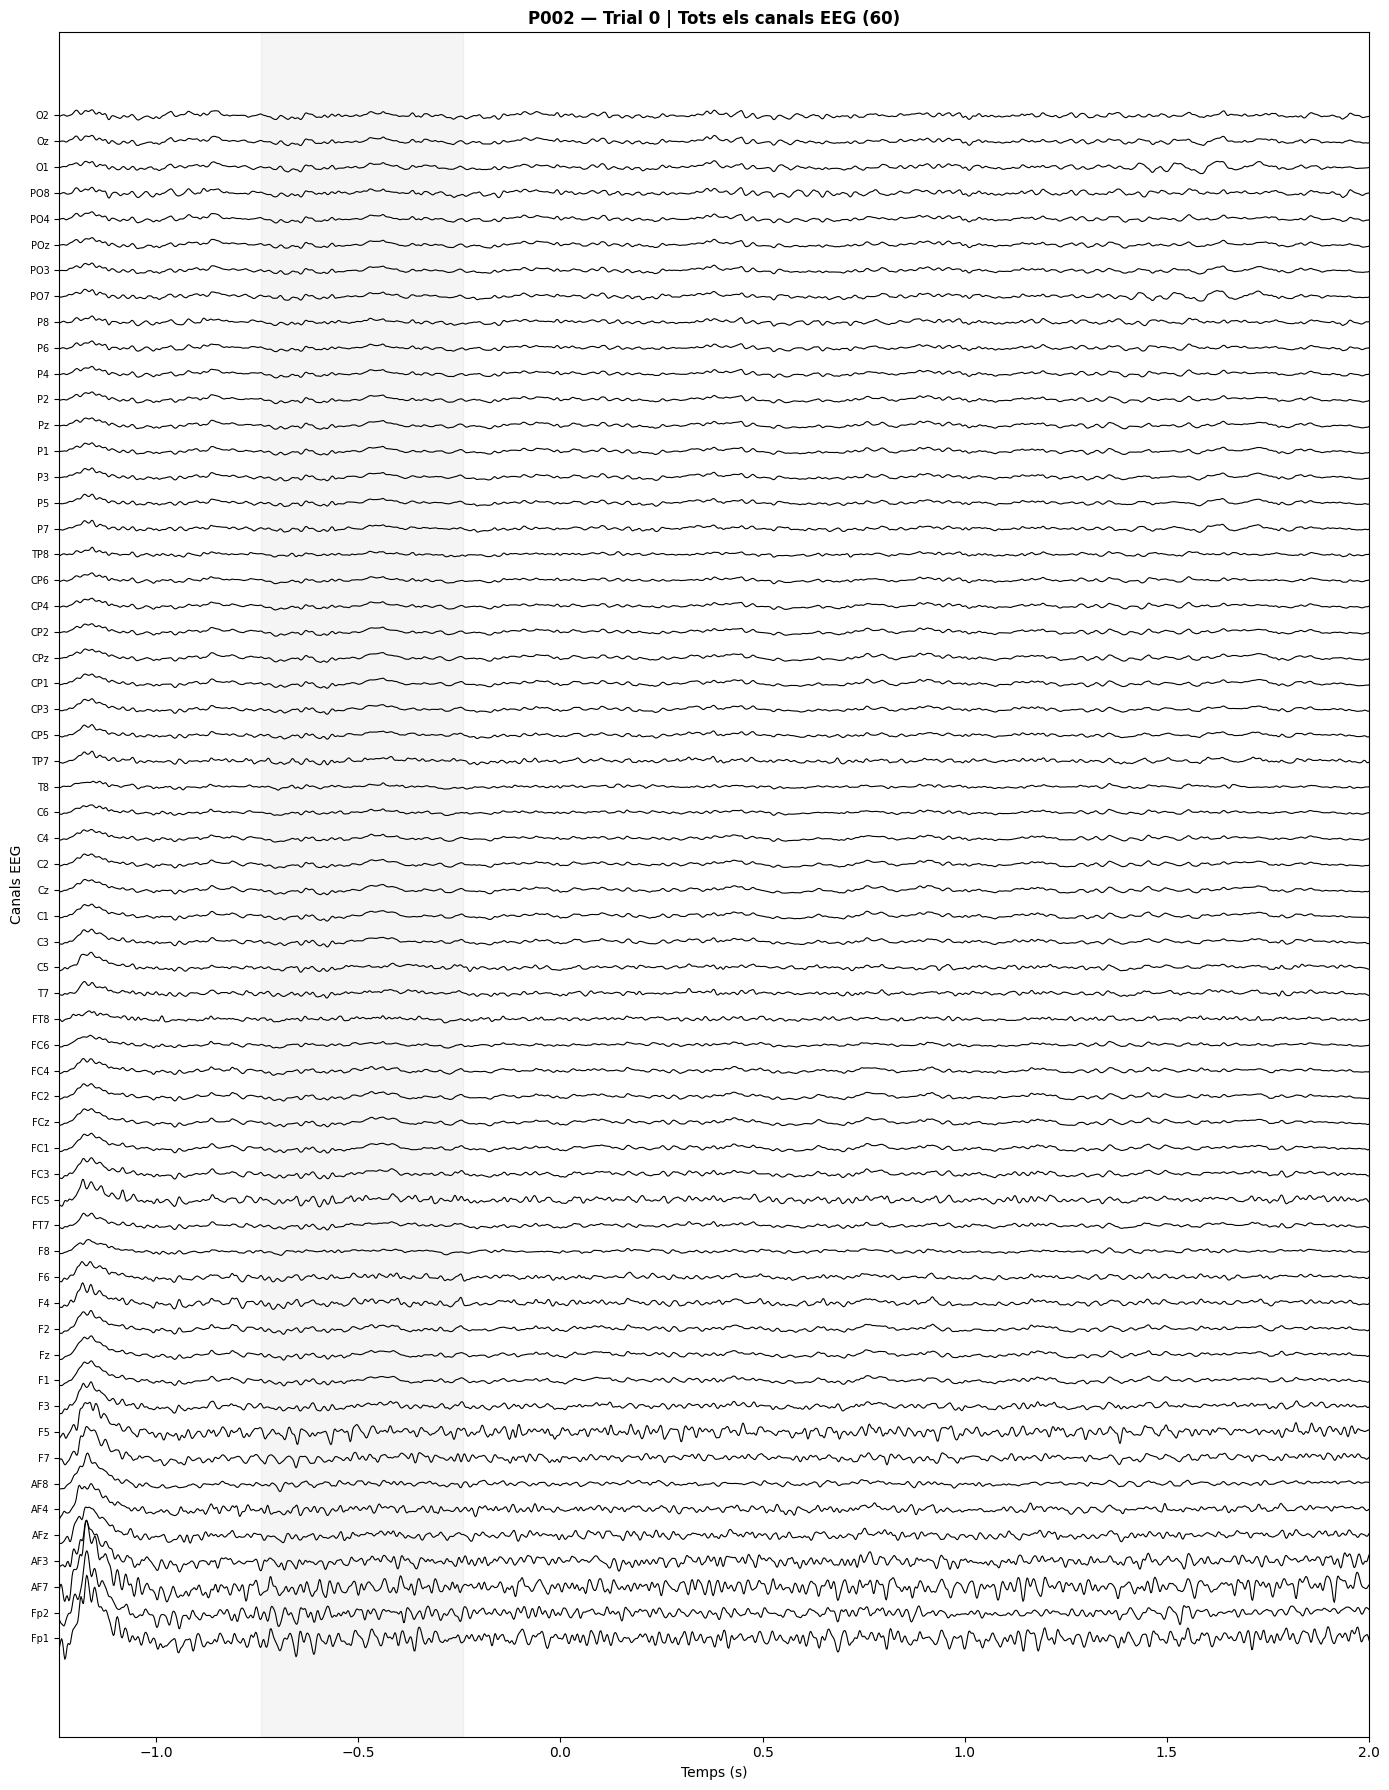

In [16]:
# Llistar i plotar tots els canals EEG de P002 per a un únic trial
ep_eeg = epochs_all.copy().pick("eeg")

trial_idx = 0
data_uv = ep_eeg.get_data()[trial_idx] * 1e6  # (n_ch, n_times) en microvolts
times = ep_eeg.times
ch_names = ep_eeg.ch_names
n_ch = len(ch_names)

# Escalat vertical automàtic perquè no se superposin massa
ptp_per_ch = np.ptp(data_uv, axis=1)
step = np.median(ptp_per_ch) * 1.8
step = step if step > 0 else 10.0
offsets = np.arange(n_ch) * step

fig, ax = plt.subplots(figsize=(14, 18))
for i, ch in enumerate(ch_names):
    ax.plot(times, data_uv[i] + offsets[i], linewidth=0.8, color="black")

ax.set_yticks(offsets)
ax.set_yticklabels(ch_names, fontsize=7)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)

ax.set_xlim([times[0], times[-1]])
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Canals EEG")
ax.set_title(f"{SUBJ} — Trial 0 | Tots els canals EEG ({n_ch})", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "trial_0_tots_canals_eeg.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Part 1: Exploració individual (P002)
Començo amb un sol participant/subjecte per familiaritzar-me amb les dades i fer plots senzills. Després passaré a fer el grand average amb tots els subjectes.

### Desbalanç de classes
Visualització de la distribució de trials per classe al conjunt de dades complet. Això permet veure ràpidament si hi ha desbalanç entre Congruent, Incongruent Pur i Incongruent Mixt.

### EDA conductual (codis CRP/CGP/IPR/IPG/IM/...)

Aquesta seccio resumeix els codis conductuals (event_1..event_12) i analitza la dominancia ocular en trials incongruents purs.

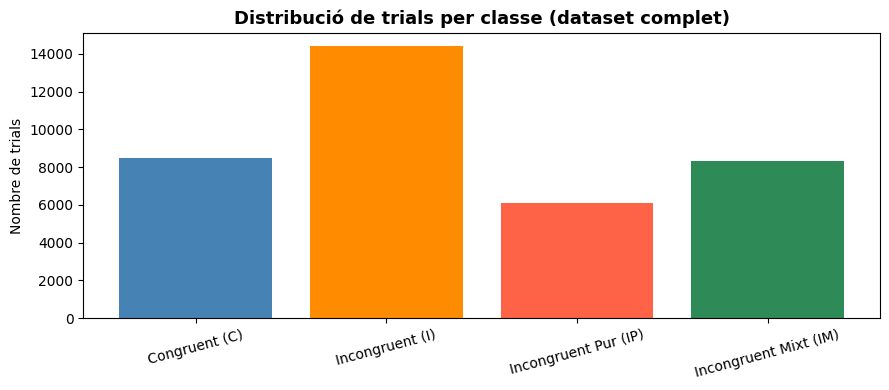

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_subjectes.csv
Recompte total per classe:
  Congruent (C)          :  8471 trials ( 37.1%)
  Incongruent (I)        : 14389 trials ( 62.9%)
  Incongruent Pur (IP)   :  6075 trials ( 26.6% del total)
  Incongruent Mixt (IM)  :  8314 trials ( 36.4% del total)


In [17]:
# Construcció única del resum conductual/dominància (si encara no existeix)
if "df_dominancia" not in globals():
    df_dominancia, comptes_classes, label_counts, globals_summary = build_behavior_dominance_summary(DATA_DIR)
    left_global = globals_summary["left_global"]
    right_global = globals_summary["right_global"]
    red_global = globals_summary["red_global"]
    green_global = globals_summary["green_global"]
else:
    # Reutilització: evitem tornar a carregar fitxers
    comptes_classes = {
        "Congruent": int((df_dominancia["CRP"] + df_dominancia["CGP"]).sum()),
        "Incongruent_Pur": int((df_dominancia["IPR"] + df_dominancia["IPG"]).sum()),
        "Incongruent_Mixt": int(df_dominancia["IM"].sum()),
    }
    comptes_classes["Incongruent"] = comptes_classes["Incongruent_Pur"] + comptes_classes["Incongruent_Mixt"]
    comptes_classes["Errors"] = int(
        (df_dominancia["CRM"] + df_dominancia["CRG"] + df_dominancia["CGM"] + df_dominancia["CGG"]).sum()
    )

c_total = comptes_classes["Congruent"]
ip_total = comptes_classes["Incongruent_Pur"]
im_total = comptes_classes["Incongruent_Mixt"]
i_total = ip_total + im_total

display_labels = [
    "Congruent (C)",
    "Incongruent (I)",
    "Incongruent Pur (IP)",
    "Incongruent Mixt (IM)",
]
display_values = [c_total, i_total, ip_total, im_total]

plt.figure(figsize=(9, 4))
plt.bar(display_labels, display_values, color=["steelblue", "darkorange", "tomato", "seagreen"])
plt.title("Distribució de trials per classe (dataset complet)", fontsize=13, fontweight="bold")
plt.ylabel("Nombre de trials")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribucio_trials_per_classe_dataset_complet.png", dpi=300, bbox_inches="tight")
plt.show()

df_dominancia.to_csv(TABLES_DIR / "dominancia_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_subjectes.csv'}")

total = c_total + i_total
print("Recompte total per classe:")
print(f"  Congruent (C)          : {c_total:5d} trials ({(100*c_total/total):5.1f}%)")
print(f"  Incongruent (I)        : {i_total:5d} trials ({(100*i_total/total):5.1f}%)")
print(f"  Incongruent Pur (IP)   : {ip_total:5d} trials ({(100*ip_total/total):5.1f}% del total)")
print(f"  Incongruent Mixt (IM)  : {im_total:5d} trials ({(100*im_total/total):5.1f}% del total)")

La classe Incongruent Pur és la menys representada, mentre que Congruent i Incongruent Mixt tenen una quantitat similar de trials. Aquest desbalanç pot afectar les anàlisis i els models predictius, per la qual cosa és important tenir-ho en compte. Mirant les dades, hi ha subjectes que són més desbalancejats que d'altres. N'hi ha que gairebé mai no tenen Incongruent Pur, però sí que tenim 30 trials garantits, ja que es van eliminar els subjectes amb menys de 30 trials per classe al preprocessament.

In [18]:
# Resum conductual/dominància (reutilitza càlcul únic si ja existeix)
if "df_dominancia" not in globals():
    df_dominancia, comptes_classes, label_counts, globals_summary = build_behavior_dominance_summary(DATA_DIR)
    left_global = globals_summary["left_global"]
    right_global = globals_summary["right_global"]
    red_global = globals_summary["red_global"]
    green_global = globals_summary["green_global"]
else:
    label_counts = {k: int(df_dominancia[k].sum()) for k in LABELS_ORDER}
    left_global = int(df_dominancia["left_eye"].sum())
    right_global = int(df_dominancia["right_eye"].sum())
    red_global = int(df_dominancia["red_count"].sum())
    green_global = int(df_dominancia["green_count"].sum())

print("Taula base de dominància preparada")
print(f"  Subjectes: {len(df_dominancia)}")
print(f"  Comptes globals ull (L/R): {left_global}/{right_global}")
print(f"  Comptes globals color (R/G): {red_global}/{green_global}")

Taula base de dominància preparada
  Subjectes: 47
  Comptes globals ull (L/R): 2796/1893
  Comptes globals color (R/G): 7303/5896


In [19]:
cols_taula = [
    "subjecte",
    "CRP",
    "CRM",
    "CRG",
    "CGP",
    "CGM",
    "CGG",
    "IPR",
    "IPG",
    "IM",
    "left_eye",
    "right_eye",
    "index_dominancia_ull",
    "p_ull",
    "red_count",
    "green_count",
    "index_dominancia_color",
    "p_color",
]

df_taula = df_dominancia[cols_taula].copy()
df_taula = df_taula.rename(
    columns={
        "index_dominancia_ull": "Índex dominància ull",
        "index_dominancia_color": "Índex dominància color",
    }
)

df_taula["Índex dominància ull"] = df_taula["Índex dominància ull"].round(3)
df_taula["Índex dominància color"] = df_taula["Índex dominància color"].round(3)
df_taula["p_ull"] = df_taula["p_ull"].round(4)
df_taula["p_color"] = df_taula["p_color"].round(4)

df_taula.to_csv(TABLES_DIR / "dominancia_detall_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_detall_subjectes.csv'}")

display(df_taula)
print(f"Files de la taula: {len(df_taula)}")

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_detall_subjectes.csv


,subjecte,CRP,CRM,CRG,CGP,CGM,CGG,IPR,IPG,IM,left_eye,right_eye,Índex dominància ull,p_ull,red_count,green_count,Índex dominància color,p_color
0,P002,81,0,0,63,0,0,88,15,137,97,6,0.883,0.0000,169,78,0.368,0.0000
1,P003,99,0,0,92,0,0,126,67,117,190,3,0.969,0.0000,225,159,0.172,0.0009
2,P004,115,0,0,103,0,0,6,59,303,36,29,0.108,0.4570,121,162,-0.145,0.0173
3,P005,84,3,0,82,2,1,72,49,169,68,53,0.124,0.2029,157,131,0.090,0.1406
4,P008,51,2,2,39,2,0,40,18,100,36,22,0.241,0.0869,91,59,0.213,0.0111
5,P009,115,1,2,109,0,1,90,31,236,81,40,0.339,0.0002,206,142,0.184,0.0007
6,P010,125,0,0,122,0,0,133,24,219,74,83,-0.057,0.5233,258,146,0.277,0.0000
7,P011,68,0,0,53,0,0,26,3,281,13,16,-0.103,0.7111,94,56,0.253,0.0024
8,P013,118,0,0,107,0,0,13,146,193,90,69,0.132,0.1124,131,253,-0.318,0.0000
9,P014,66,3,1,61,5,1,18,51,210,22,47,-0.362,0.0035,85,113,-0.141,0.0547


Files de la taula: 47


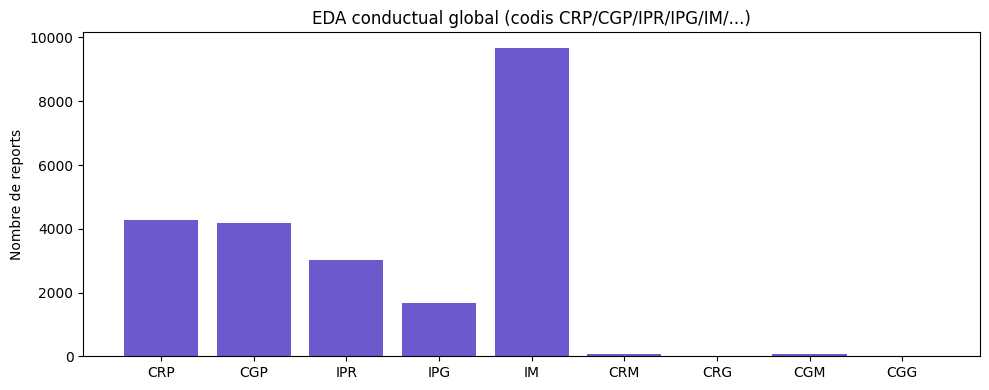

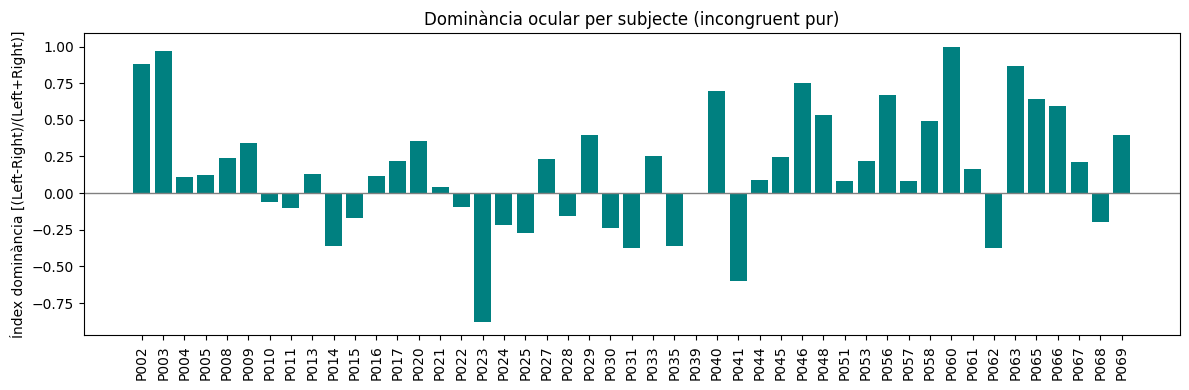

In [20]:
# Plot 1: distribució codis conductuals globals
x = np.arange(len(LABELS_ORDER))
vals = [label_counts[k] for k in LABELS_ORDER]

plt.figure(figsize=(10, 4))
plt.bar(x, vals, color="slateblue")
plt.xticks(x, LABELS_ORDER)
plt.ylabel("Nombre de reports")
plt.title("EDA conductual global (codis CRP/CGP/IPR/IPG/IM/...)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_conductual_global_codis.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: índex de dominància ocular per subjecte
plt.figure(figsize=(12, 4))
plt.axhline(0, color="gray", linewidth=1)
plt.bar(df_dominancia["subjecte"], df_dominancia["index_dominancia_ull"], color="teal")
plt.ylabel("Índex dominància [(Left-Right)/(Left+Right)]")
plt.title("Dominància ocular per subjecte (incongruent pur)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_ocular_per_subjecte_incongruent_pur.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
eye_test_global = binomtest(left_global, n=left_global + right_global, p=0.5, alternative="two-sided")
color_test_global = binomtest(red_global, n=red_global + green_global, p=0.5, alternative="two-sided")

eye_ci = eye_test_global.proportion_ci(confidence_level=0.95, method="exact")
color_ci = color_test_global.proportion_ci(confidence_level=0.95, method="exact")

p_ull = left_global / (left_global + right_global)
p_color = red_global / (red_global + green_global)

idx_ull_global = 2 * p_ull - 1
idx_color_global = 2 * p_color - 1

print("Test global de Dominància ocular (incongruent pur)")
print(f"  Left-eye coherent : {left_global}")
print(f"  Right-eye coherent: {right_global}")
print(f"  Proporció esquerre: {p_ull:.3f} (IC95% [{eye_ci.low:.3f}, {eye_ci.high:.3f}])")
print(f"  Índex global      : {idx_ull_global:.3f}")
print(f"  p-valor binomial  : {eye_test_global.pvalue:.4e}")

print("\nTest global de Dominància de color")
print(f"  Vermell : {red_global}")
print(f"  Verd    : {green_global}")
print(f"  Proporció vermell: {p_color:.3f} (IC95% [{color_ci.low:.3f}, {color_ci.high:.3f}])")
print(f"  Índex global      : {idx_color_global:.3f}")
print(f"  p-valor binomial  : {color_test_global.pvalue:.4e}")

Test global de Dominància ocular (incongruent pur)
  Left-eye coherent : 2796
  Right-eye coherent: 1893
  Proporció esquerre: 0.596 (IC95% [0.582, 0.610])
  Índex global      : 0.193
  p-valor binomial  : 7.3452e-40

Test global de Dominància de color
  Vermell : 7303
  Verd    : 5896
  Proporció vermell: 0.553 (IC95% [0.545, 0.562])
  Índex global      : 0.107
  p-valor binomial  : 1.6869e-34


In [22]:
# Comparació explícita: pooled/ponderat vs macro-average
subj_ull = df_dominancia[df_dominancia["n_ull"] > 0].copy()
subj_color = df_dominancia[df_dominancia["n_color"] > 0].copy()

subj_ull["p_left_subj"] = subj_ull["left_eye"] / subj_ull["n_ull"]
subj_color["p_red_subj"] = subj_color["red_count"] / subj_color["n_color"]

# Pooled (equivalent a ponderat per n)
p_ull_pooled = left_global / (left_global + right_global)
p_color_pooled = red_global / (red_global + green_global)

# Macro-average (mateix pes per subjecte)
p_ull_macro = subj_ull["p_left_subj"].mean()
p_color_macro = subj_color["p_red_subj"].mean()

# Weighted-average explícit (ha de coincidir amb pooled)
p_ull_weighted = np.average(subj_ull["p_left_subj"], weights=subj_ull["n_ull"])
p_color_weighted = np.average(subj_color["p_red_subj"], weights=subj_color["n_color"])

print("Comparació de mesures globals")
print("  Dominància ocular (proporció esquerre):")
print(f"    Pooled / ponderat per n : {p_ull_pooled:.4f}")
print(f"    Weighted average        : {p_ull_weighted:.4f}")
print(f"    Macro-average           : {p_ull_macro:.4f}")
print(f"    Diferència macro-pooled : {p_ull_macro - p_ull_pooled:+.4f}")

print("\n  Dominància de color (proporció vermell):")
print(f"    Pooled / ponderat per n : {p_color_pooled:.4f}")
print(f"    Weighted average        : {p_color_weighted:.4f}")
print(f"    Macro-average           : {p_color_macro:.4f}")
print(f"    Diferència macro-pooled : {p_color_macro - p_color_pooled:+.4f}")

Comparació de mesures globals
  Dominància ocular (proporció esquerre):
    Pooled / ponderat per n : 0.5963
    Weighted average        : 0.5963
    Macro-average           : 0.5819
    Diferència macro-pooled : -0.0143

  Dominància de color (proporció vermell):
    Pooled / ponderat per n : 0.5533
    Weighted average        : 0.5533
    Macro-average           : 0.5542
    Diferència macro-pooled : +0.0009


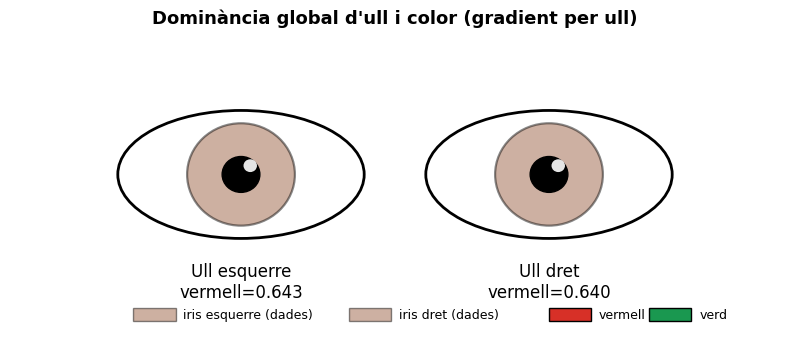

Resum utilitzat pel plot d'ulls
  Ull esquerre: red=1798, green=998, proporció vermell=0.643, intensitat=0.286
  Ull dret    : red=1212, green=681, proporció vermell=0.640, intensitat=0.281


In [23]:
# Dominància global visual (ulls + color), amb gradient per ull
left_red = int(df_dominancia["left_red"].sum())
left_green = int(df_dominancia["left_green"].sum())
right_red = int(df_dominancia["right_red"].sum())
right_green = int(df_dominancia["right_green"].sum())

left_total = max(left_red + left_green, 1)
right_total = max(right_red + right_green, 1)
left_red_ratio = left_red / left_total
right_red_ratio = right_red / right_total

left_intensity = 2 * abs(left_red_ratio - 0.5)
right_intensity = 2 * abs(right_red_ratio - 0.5)
left_iris_alpha = 0.25 + 0.75 * left_intensity
right_iris_alpha = 0.25 + 0.75 * right_intensity

# Color gradient verd->vermell segons proporció de vermell per ull
red_rgb = np.array([0.84, 0.18, 0.15])
green_rgb = np.array([0.10, 0.60, 0.31])
left_iris_color = (1 - left_red_ratio) * green_rgb + left_red_ratio * red_rgb
right_iris_color = (1 - right_red_ratio) * green_rgb + right_red_ratio * red_rgb

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.2)
ax.axis("off")


def draw_eye(cx, cy, width, height, iris_color, iris_alpha):
    sclera = Ellipse((cx, cy), width, height, facecolor="white", edgecolor="black", linewidth=2, alpha=1.0)
    iris = Circle(
        (cx, cy), radius=height * 0.40, facecolor=iris_color, edgecolor="black", linewidth=1.6, alpha=iris_alpha
    )
    pupil = Circle((cx, cy), radius=height * 0.14, facecolor="black", edgecolor="black", linewidth=1)
    glare = Circle((cx + 0.12, cy + 0.12), radius=height * 0.05, facecolor="white", edgecolor="none", alpha=0.9)
    ax.add_patch(sclera)
    ax.add_patch(iris)
    ax.add_patch(pupil)
    ax.add_patch(glare)


draw_eye(3.0, 2.25, 3.2, 1.75, left_iris_color, left_iris_alpha)
draw_eye(7.0, 2.25, 3.2, 1.75, right_iris_color, right_iris_alpha)

ax.text(3.0, 1.05, f"Ull esquerre\nvermell={left_red_ratio:.3f}", ha="center", va="top", fontsize=12)
ax.text(7.0, 1.05, f"Ull dret\nvermell={right_red_ratio:.3f}", ha="center", va="top", fontsize=12)

legend_y = 0.24

ax.add_patch(
    Rectangle((1.6, legend_y), 0.55, 0.18, facecolor=left_iris_color, alpha=left_iris_alpha, edgecolor="black")
)
ax.text(2.25, legend_y + 0.09, "iris esquerre (dades)", va="center", fontsize=9)

ax.add_patch(
    Rectangle((4.4, legend_y), 0.55, 0.18, facecolor=right_iris_color, alpha=right_iris_alpha, edgecolor="black")
)
ax.text(5.05, legend_y + 0.09, "iris dret (dades)", va="center", fontsize=9)

ax.add_patch(Rectangle((7.0, legend_y), 0.55, 0.18, facecolor="#d73027", alpha=1.0, edgecolor="black"))
ax.text(7.65, legend_y + 0.09, "vermell", va="center", fontsize=9)

ax.add_patch(Rectangle((8.3, legend_y), 0.55, 0.18, facecolor="#1a9850", alpha=1.0, edgecolor="black"))
ax.text(8.95, legend_y + 0.09, "verd", va="center", fontsize=9)

ax.set_title("Dominància global d'ull i color (gradient per ull)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_global_ull_color_gradient.png", dpi=300, bbox_inches="tight")
plt.show()

print("Resum utilitzat pel plot d'ulls")
print(
    f"  Ull esquerre: red={left_red}, green={left_green}, proporció vermell={left_red_ratio:.3f}, intensitat={left_intensity:.3f}"
)
print(
    f"  Ull dret    : red={right_red}, green={right_green}, proporció vermell={right_red_ratio:.3f}, intensitat={right_intensity:.3f}"
)

#### Visualització estilitzada de dominància global (ulls)

Aquest gràfic representa dos ulls: l'opacitat de cada ull codifica la dominància ocular (esquerre/dret) i el color de l'iris codifica la predominància de color (vermell/verd), modulada per l'evidència estadística global.

Subjectes amb biaix significatiu (p < 0.05):
  Ull   : 28/47
  Color : 29/47
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_significanca_subjectes.csv


,subjecte,left_eye,right_eye,Índex dominància ull,IC95% ull (low),IC95% ull (high),p_ull,ull_predominant,sig_ull,red_count,green_count,Índex dominància color,IC95% color (low),IC95% color (high),p_color,color_predominant,sig_color
0,P002,97,6,0.883495,0.877513,0.978325,3.001586e-22,Esquerre,True,169,78,0.368421,0.622257,0.741677,6.990574e-09,Vermell,True
1,P003,190,3,0.968912,0.955248,0.996783,1.909063e-52,Esquerre,True,225,159,0.171875,0.534865,0.635675,8.864316e-04,Vermell,True
2,P004,36,29,0.107692,0.425319,0.677306,4.570208e-01,Esquerre,False,121,162,-0.144876,0.369183,0.487473,1.726415e-02,Verd,True
3,P005,68,53,0.123967,0.468865,0.651996,2.029243e-01,Esquerre,False,157,131,0.090278,0.485681,0.603659,1.405792e-01,Vermell,False
4,P008,36,22,0.241379,0.483718,0.744892,8.694890e-02,Esquerre,False,91,59,0.213333,0.523685,0.685347,1.112159e-02,Vermell,True
5,P009,81,40,0.338843,0.578086,0.752242,2.442170e-04,Esquerre,True,206,142,0.183908,0.538279,0.644050,7.100480e-04,Vermell,True
6,P010,74,83,-0.057325,0.391278,0.552500,5.233008e-01,Dret,False,258,146,0.277228,0.589650,0.685530,2.744343e-08,Vermell,True
7,P011,13,16,-0.103448,0.264455,0.643061,7.110711e-01,Dret,False,94,56,0.253333,0.544036,0.704188,2.405516e-03,Vermell,True
8,P013,90,69,0.132075,0.485237,0.644330,1.124301e-01,Esquerre,False,131,253,-0.317708,0.293811,0.390952,4.773196e-10,Verd,True
9,P014,22,47,-0.362319,0.211748,0.442054,3.544813e-03,Dret,True,85,113,-0.141414,0.359350,0.501385,5.473388e-02,Verd,False


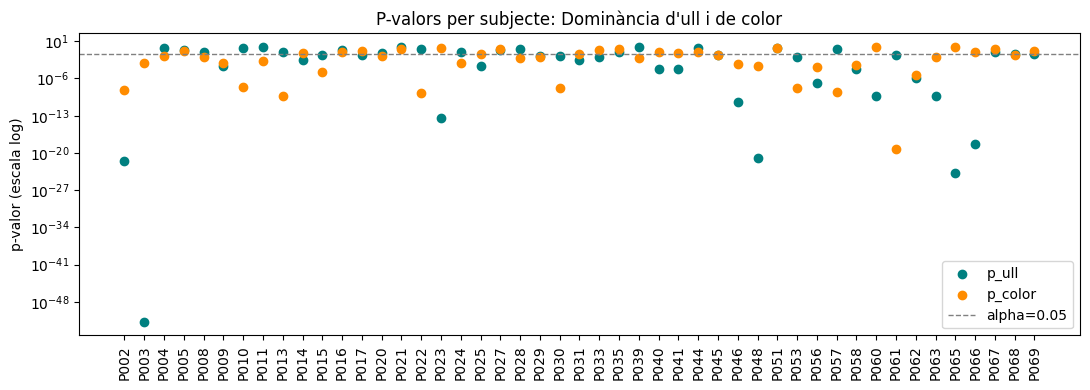

In [24]:
alpha = ALPHA

# Criteris de preferència (només descriptius)
df_stats = df_dominancia.copy()
df_stats["ull_predominant"] = np.where(
    df_stats["index_dominancia_ull"] > 0,
    "Esquerre",
    np.where(df_stats["index_dominancia_ull"] < 0, "Dret", "Equilibrat"),
)
df_stats["color_predominant"] = np.where(
    df_stats["index_dominancia_color"] > 0,
    "Vermell",
    np.where(df_stats["index_dominancia_color"] < 0, "Verd", "Equilibrat"),
)

# IC95% exactes per subjecte (si no venen del dataframe principal)
if "ci95_ull_low" not in df_stats.columns:
    df_stats[["ci95_ull_low", "ci95_ull_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_ull"])),
        axis=1,
    )
    df_stats[["ci95_color_low", "ci95_color_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

m_ull = int((df_stats["n_ull"] > 0).sum())
m_color = int((df_stats["n_color"] > 0).sum())
df_stats["sig_ull"] = (df_stats["p_ull"] < alpha) & (df_stats["n_ull"] > 0)
df_stats["sig_color"] = (df_stats["p_color"] < alpha) & (df_stats["n_color"] > 0)

print("Subjectes amb biaix significatiu (p < 0.05):")
print(f"  Ull   : {int(df_stats['sig_ull'].sum())}/{m_ull}")
print(f"  Color : {int(df_stats['sig_color'].sum())}/{m_color}")

cols_stats = [
    "subjecte",
    "left_eye",
    "right_eye",
    "index_dominancia_ull",
    "ci95_ull_low",
    "ci95_ull_high",
    "p_ull",
    "ull_predominant",
    "sig_ull",
    "red_count",
    "green_count",
    "index_dominancia_color",
    "ci95_color_low",
    "ci95_color_high",
    "p_color",
    "color_predominant",
    "sig_color",
]

df_stats_show = (
    df_stats[cols_stats]
    .rename(
        columns={
            "index_dominancia_ull": "Índex dominància ull",
            "ci95_ull_low": "IC95% ull (low)",
            "ci95_ull_high": "IC95% ull (high)",
            "index_dominancia_color": "Índex dominància color",
            "ci95_color_low": "IC95% color (low)",
            "ci95_color_high": "IC95% color (high)",
        }
    )
    .sort_values("subjecte")
    .reset_index(drop=True)
)

df_stats_show.to_csv(TABLES_DIR / "dominancia_significanca_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_significanca_subjectes.csv'}")

display(df_stats_show)

# Mini-visualització de p-valors per inspecció ràpida
plt.figure(figsize=(11, 4))
plt.scatter(df_stats["subjecte"], df_stats["p_ull"], label="p_ull", color="teal")
plt.scatter(df_stats["subjecte"], df_stats["p_color"], label="p_color", color="darkorange")
plt.axhline(alpha, color="gray", linestyle="--", linewidth=1, label="alpha=0.05")
plt.yscale("log")
plt.ylabel("p-valor (escala log)")
plt.title("P-valors per subjecte: Dominància d'ull i de color")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p_valors_dominancia_ull_color_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 2: Dominància i preguntes de recerca (fase inicial)

Aquest bloc amplia l'anàlisi de dominància amb visualitzacions d'intervals de confiança per subjecte i comparació pooled vs macro-average.

In [25]:
# Q1-Q2: significació individual (criteri simple p<0.05)
if "df_dominancia" not in globals():
    raise RuntimeError("Executa primer la cel·la de preparació EDA conductual (on es crea df_dominancia).")

df_infer = df_dominancia.copy()

m_ull = int((df_infer["n_ull"] > 0).sum())
m_color = int((df_infer["n_color"] > 0).sum())

print("Significació per subjecte")
print(f"  Ull   p<0.05 : {int((df_infer['p_ull'] < 0.05).sum())}/{m_ull}")
print(f"  Color p<0.05 : {int((df_infer['p_color'] < 0.05).sum())}/{m_color}")

Significació per subjecte
  Ull   p<0.05 : 28/47
  Color p<0.05 : 29/47


### Forest plot per subjecte (proporció + IC95%)

Comparació visual de dominància ocular i de color per subjecte, amb intervals de confiança exactes.

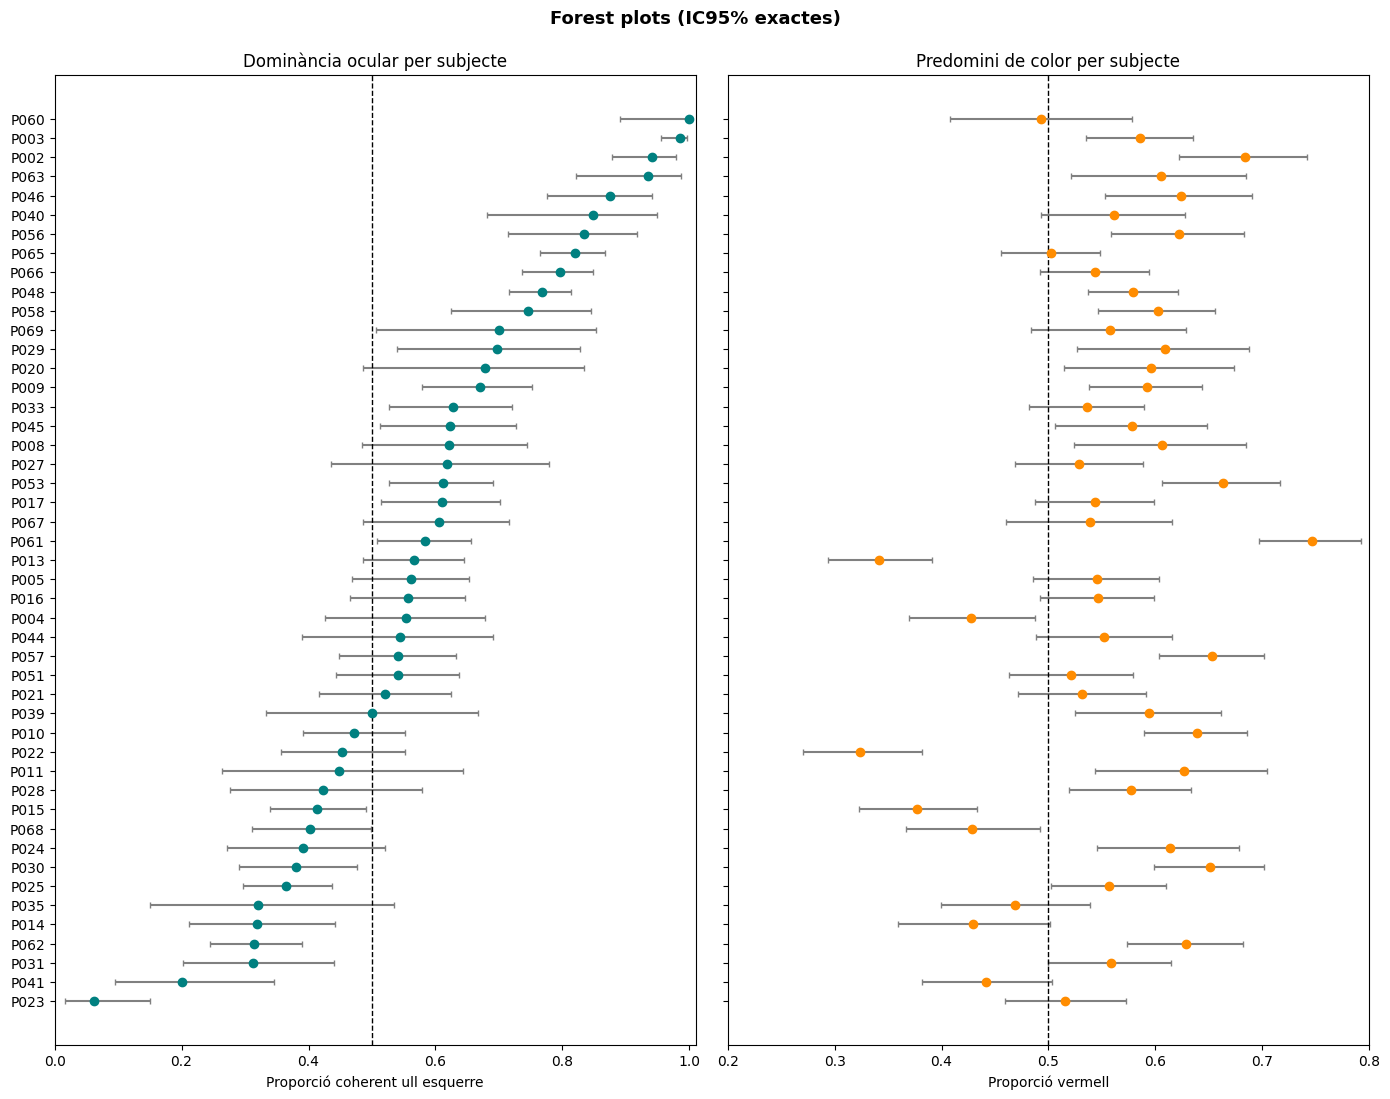

In [26]:
# Construcció de dades de forest plot (ull i color) reutilitzant IC95% ja calculats
forest = df_dominancia.copy()
forest["p_left"] = forest["left_eye"] / forest["n_ull"]
forest["p_red"] = forest["red_count"] / forest["n_color"]

# Garantia mínima per compatibilitat amb versions antigues del dataframe
if "ci95_ull_low" not in forest.columns:
    forest[["ci95_ull_low", "ci95_ull_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_ull"])),
        axis=1,
    )
    forest[["ci95_color_low", "ci95_color_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

forest = forest.sort_values("p_left").reset_index(drop=True)
y = np.arange(len(forest))

fig, axes = plt.subplots(1, 2, figsize=(14, 11), sharey=True)

# Dominància ocular
x = forest["p_left"].values
xerr = np.vstack([x - forest["ci95_ull_low"].values, forest["ci95_ull_high"].values - x])
axes[0].errorbar(x, y, xerr=xerr, fmt="o", color="teal", ecolor="gray", capsize=2)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Dominància ocular per subjecte")
axes[0].set_xlabel("Proporció coherent ull esquerre")
axes[0].set_yticks(y)
axes[0].set_yticklabels(forest["subjecte"])
axes[0].set_xlim(0, 1.01)

# Predomini de color
xc = forest["p_red"].values
xerrc = np.vstack([xc - forest["ci95_color_low"].values, forest["ci95_color_high"].values - xc])
axes[1].errorbar(xc, y, xerr=xerrc, fmt="o", color="darkorange", ecolor="gray", capsize=2)
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Predomini de color per subjecte")
axes[1].set_xlabel("Proporció vermell")
axes[1].set_xlim(0.2, 0.8)

plt.suptitle("Forest plots (IC95% exactes)", y=0.995, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "forest_plots_ic95_exactes.png", dpi=300, bbox_inches="tight")
plt.show()

### Mitjana per subjecte (macro-average)

Mostrem una estimació simple amb la **mitjana normal per subjecte** de la proporció de dominància (ull i color), amb IC95% bootstrap.

Mitjana normal per subjecte (macro-average)
  Ull   (proporció esquerre): 0.5819  IC95% [0.5248, 0.6399]
  Color (proporció vermell) : 0.5542  IC95% [0.5290, 0.5785]


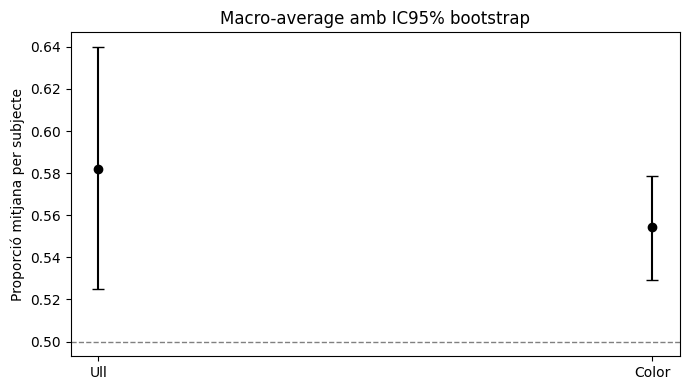

In [27]:
rng = np.random.default_rng(42)


def bootstrap_macro_ci(success_col, total_col, n_boot=5000):
    d = df_dominancia[[success_col, total_col]].dropna().copy()
    d = d[d[total_col] > 0].reset_index(drop=True)
    p_subj = d[success_col] / d[total_col]
    macro = p_subj.mean()

    boot = np.empty(n_boot)
    n = len(p_subj)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = p_subj.iloc[idx].mean()

    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    return macro, ci_low, ci_high


macro_ull, ull_lo, ull_hi = bootstrap_macro_ci("left_eye", "n_ull")
macro_color, col_lo, col_hi = bootstrap_macro_ci("red_count", "n_color")

print("Mitjana normal per subjecte (macro-average)")
print(f"  Ull   (proporció esquerre): {macro_ull:.4f}  IC95% [{ull_lo:.4f}, {ull_hi:.4f}]")
print(f"  Color (proporció vermell) : {macro_color:.4f}  IC95% [{col_lo:.4f}, {col_hi:.4f}]")

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Ull", "Color"]
means = [macro_ull, macro_color]
ci_low_err = [macro_ull - ull_lo, macro_color - col_lo]
ci_high_err = [ull_hi - macro_ull, col_hi - macro_color]
ax.errorbar(labels, means, yerr=[ci_low_err, ci_high_err], fmt="o", color="black", capsize=4)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Proporció mitjana per subjecte")
ax.set_title("Macro-average amb IC95% bootstrap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "macro_average_ic95_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

### Relació entre dominància ocular i de color

Pregunta: els subjectes més dominants per ull també tendeixen a ser més dominants per color?

Correlació entre índex de dominància ocular i de color (Spearman)
  rho = 0.240
  p   = 0.104


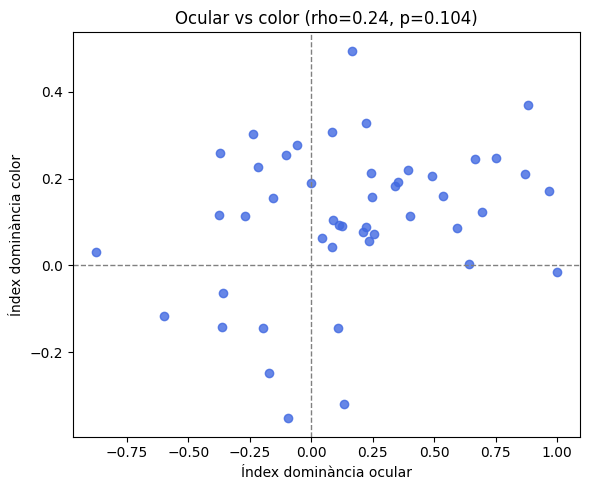

In [28]:
corr_df = df_dominancia[["subjecte", "index_dominancia_ull", "index_dominancia_color"]].dropna()
rho, p_corr = spearmanr(corr_df["index_dominancia_ull"], corr_df["index_dominancia_color"])

print("Correlació entre índex de dominància ocular i de color (Spearman)")
print(f"  rho = {rho:.3f}")
print(f"  p   = {p_corr:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    corr_df["index_dominancia_ull"],
    corr_df["index_dominancia_color"],
    color="royalblue",
    alpha=0.8,
)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Índex dominància ocular")
ax.set_ylabel("Índex dominància color")
ax.set_title(f"Ocular vs color (rho={rho:.2f}, p={p_corr:.3f})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlacio_dominancia_ocular_vs_color.png", dpi=300, bbox_inches="tight")
plt.show()

## Histogrames de classes per subjecte

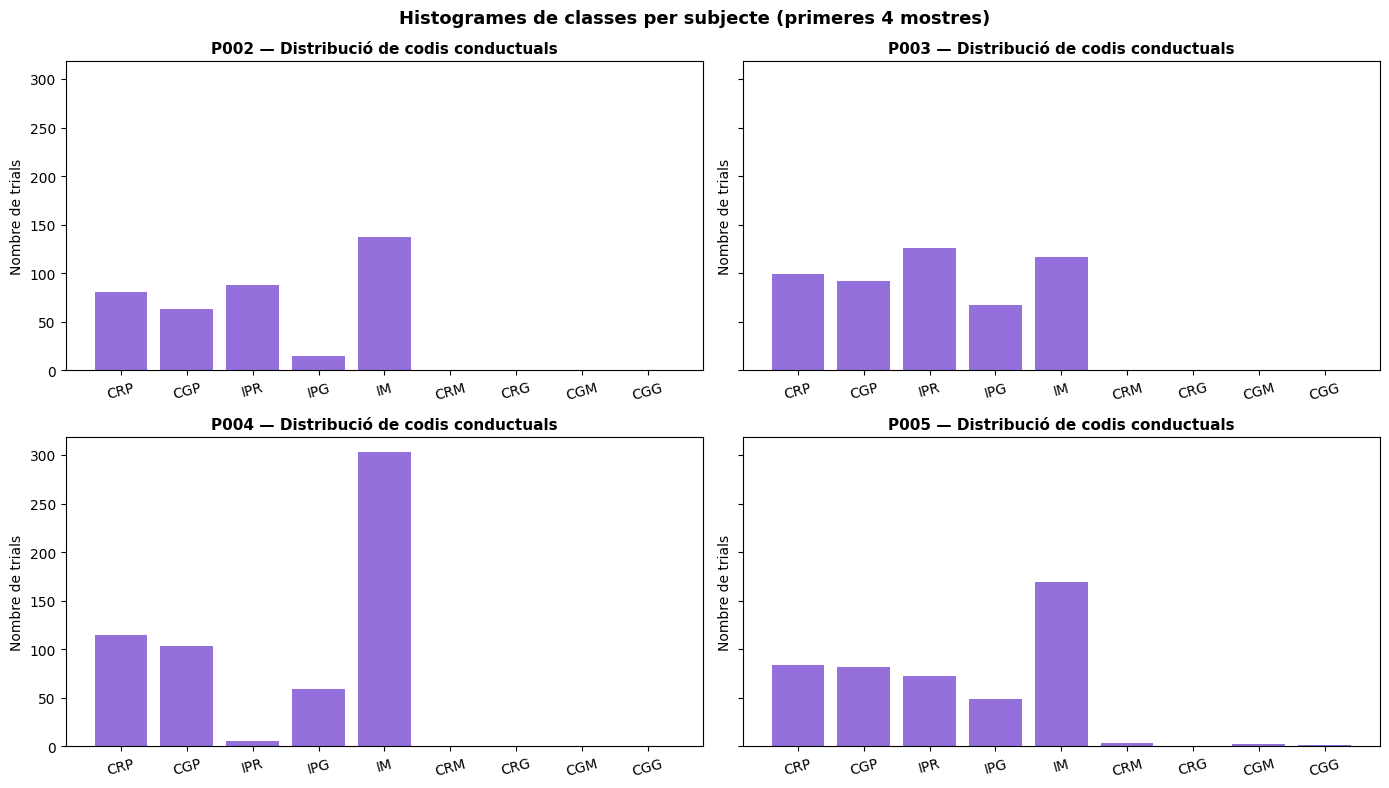

In [29]:
# Histogrames de classes per subjecte en una sola figura (grid 2x2)
subjectes_plot = df_dominancia["subjecte"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()

for ax, subj in zip(axes, subjectes_plot):
    subj_data = df_dominancia[df_dominancia["subjecte"] == subj]
    counts = subj_data[LABELS_ORDER].values.flatten()
    ax.bar(LABELS_ORDER, counts, color="mediumpurple")
    ax.set_title(f"{subj} — Distribució de codis conductuals", fontsize=11, fontweight="bold")
    ax.set_ylabel("Nombre de trials")
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("Histogrames de classes per subjecte (primeres 4 mostres)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

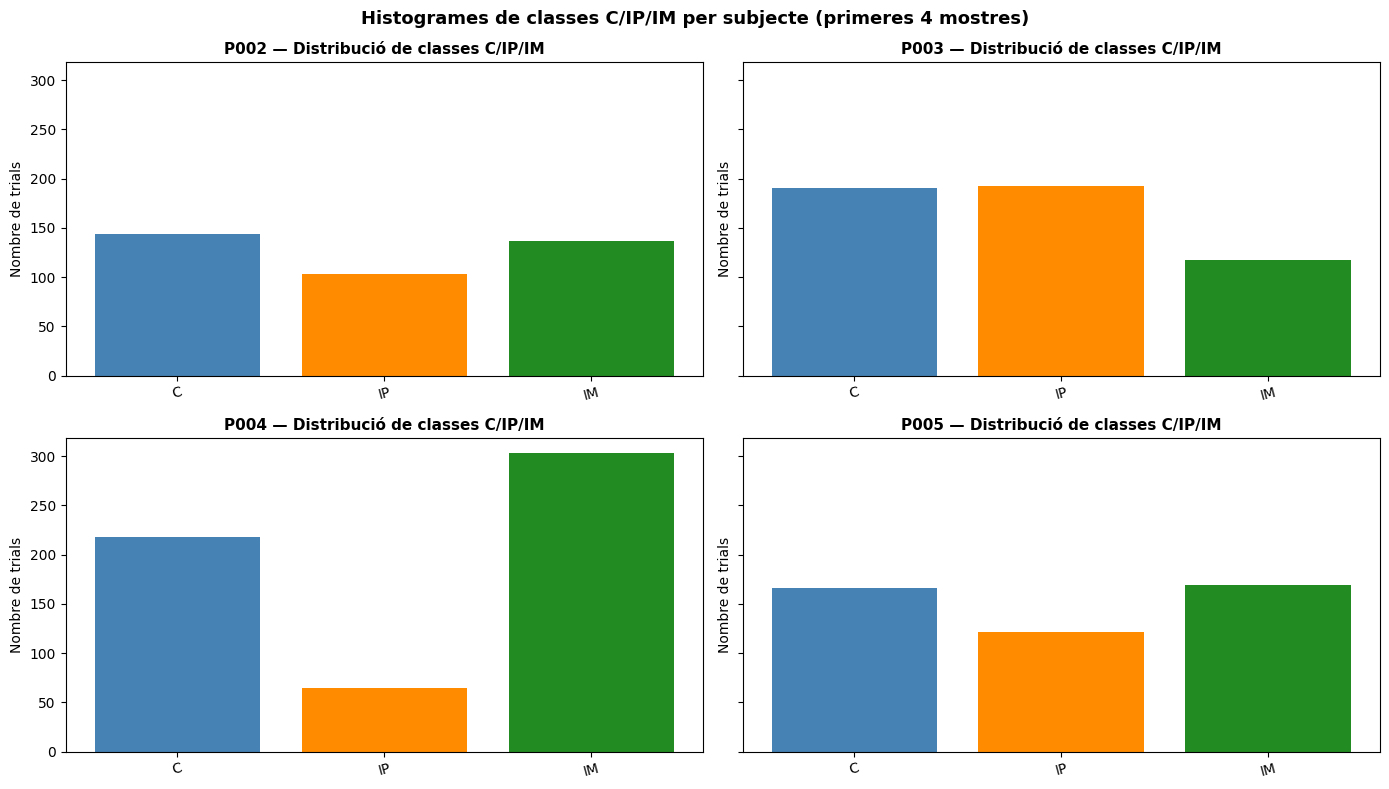

In [30]:
# Histogrames de classes per subjecte (C, IP, IM) en una sola figura (grid 2x2)
subjectes_plot = df_dominancia["subjecte"].head(4).tolist()
classes_plot = ["C", "IP", "IM"]

class_map = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
class_colors = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()
for ax, subj in zip(axes, subjectes_plot):
    subj_data = df_dominancia[df_dominancia["subjecte"] == subj]
    counts = [float(subj_data[class_map[cls]].sum(axis=1).iloc[0]) for cls in classes_plot]

    ax.bar(classes_plot, counts, color=[class_colors[c] for c in classes_plot])
    ax.set_title(f"{subj} — Distribució de classes C/IP/IM", fontsize=11, fontweight="bold")
    ax.set_ylabel("Nombre de trials")
    ax.tick_params(axis="x", rotation=15)

# Si hi ha menys de 4 subjectes, amaga subplots buits
for ax in axes[len(subjectes_plot) :]:
    ax.axis("off")

fig.suptitle("Histogrames de classes C/IP/IM per subjecte (primeres 4 mostres)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_c_ip_im_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

### Anàlisi complementària C/IP/IM (subjecte + global)

Aquest bloc afegeix plots per veure millor la relació entre C, IP i IM:
1. Patró per subjecte en percentatge (stacked) i heatmap.
2. Distribució global entre subjectes (boxplot + mitjana amb IC95%).
3. Tendències ordenades per subjecte.
4. Correlacions entre proporcions C/IP/IM.

In [31]:
# Configuració compartida C/IP/IM + taula resum (execució lineal)
CIPIM_CLASSES = ["C", "IP", "IM"]
CIPIM_CLASS_MAP = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
CIPIM_COLORS = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

df_cipim = pd.DataFrame({"subjecte": df_dominancia["subjecte"]})
for cls in CIPIM_CLASSES:
    df_cipim[cls] = df_dominancia[CIPIM_CLASS_MAP[cls]].sum(axis=1)

df_cipim["total_cipim"] = df_cipim[CIPIM_CLASSES].sum(axis=1)
for cls in CIPIM_CLASSES:
    df_cipim[f"p_{cls}"] = df_cipim[cls] / df_cipim["total_cipim"]

df_cipim = df_cipim.sort_values("subjecte").reset_index(drop=True)

In [32]:
df_cipim.to_csv(TABLES_DIR / "c_ip_im_resum_subjectes.csv", index=False)
print(f"Desada taula: {TABLES_DIR / 'c_ip_im_resum_subjectes.csv'}")
print(f"Subjectes inclosos: {len(df_cipim)}")

display(df_cipim.head())

Desada taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\c_ip_im_resum_subjectes.csv
Subjectes inclosos: 47


,subjecte,C,IP,IM,total_cipim,p_C,p_IP,p_IM
0,P002,144,103,137,384,0.375000,0.268229,0.356771
1,P003,191,193,117,501,0.381238,0.385230,0.233533
2,P004,218,65,303,586,0.372014,0.110922,0.517065
3,P005,166,121,169,456,0.364035,0.265351,0.370614
4,P008,90,58,100,248,0.362903,0.233871,0.403226


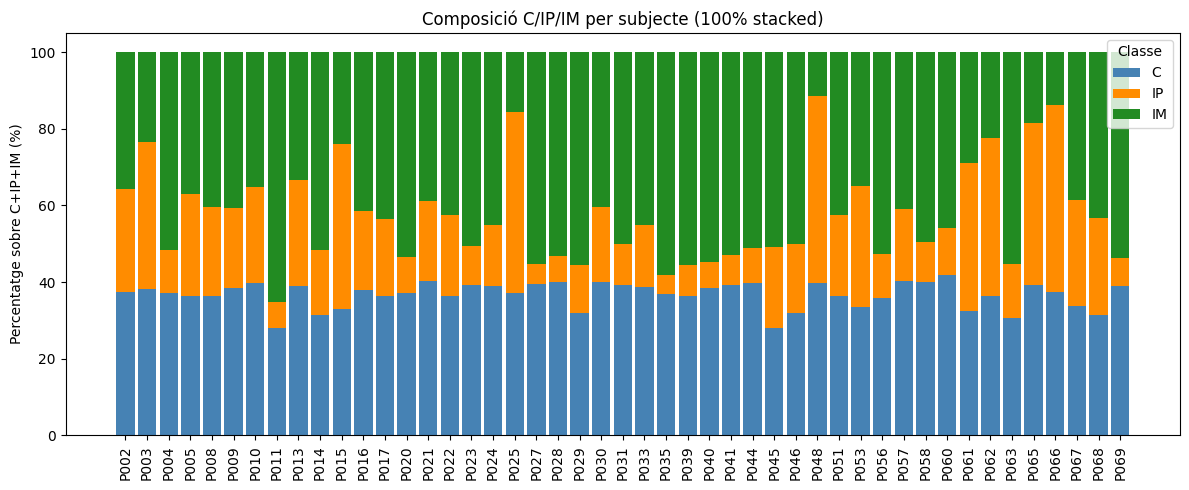

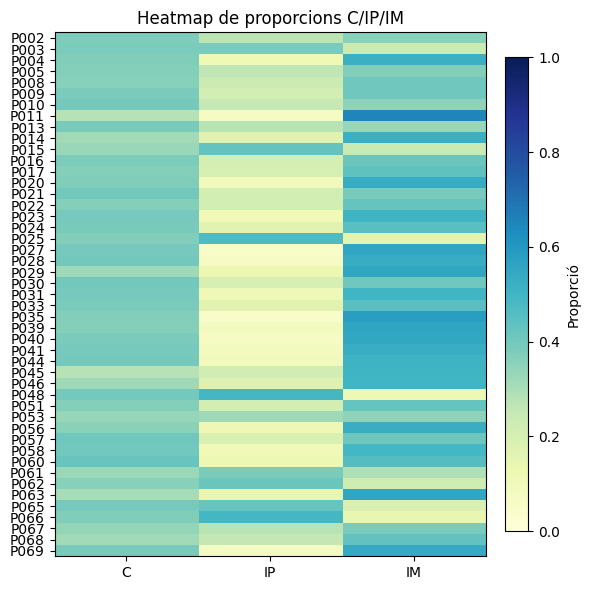

In [33]:
# Plot 1A: stacked bar en percentatge per subjecte
subjectes = df_cipim["subjecte"].tolist()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(subjectes))
bottom = np.zeros(len(subjectes))

for cls in CIPIM_CLASSES:
    vals = df_cipim[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(subjectes, rotation=90)
ax.set_ylabel("Percentatge sobre C+IP+IM (%)")
ax.set_title("Composició C/IP/IM per subjecte (100% stacked)")
ax.legend(title="Classe")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_stacked_percentatge.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 1B: heatmap de proporcions per subjecte
heat_data = df_cipim[["p_C", "p_IP", "p_IM"]].values

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(heat_data, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(CIPIM_CLASSES)))
ax.set_xticklabels(CIPIM_CLASSES)
ax.set_yticks(np.arange(len(subjectes)))
ax.set_yticklabels(subjectes)
ax.set_title("Heatmap de proporcions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="Proporció")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_heatmap_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\nils\AppData\Local\Temp\ipykernel_16144\542779081.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)


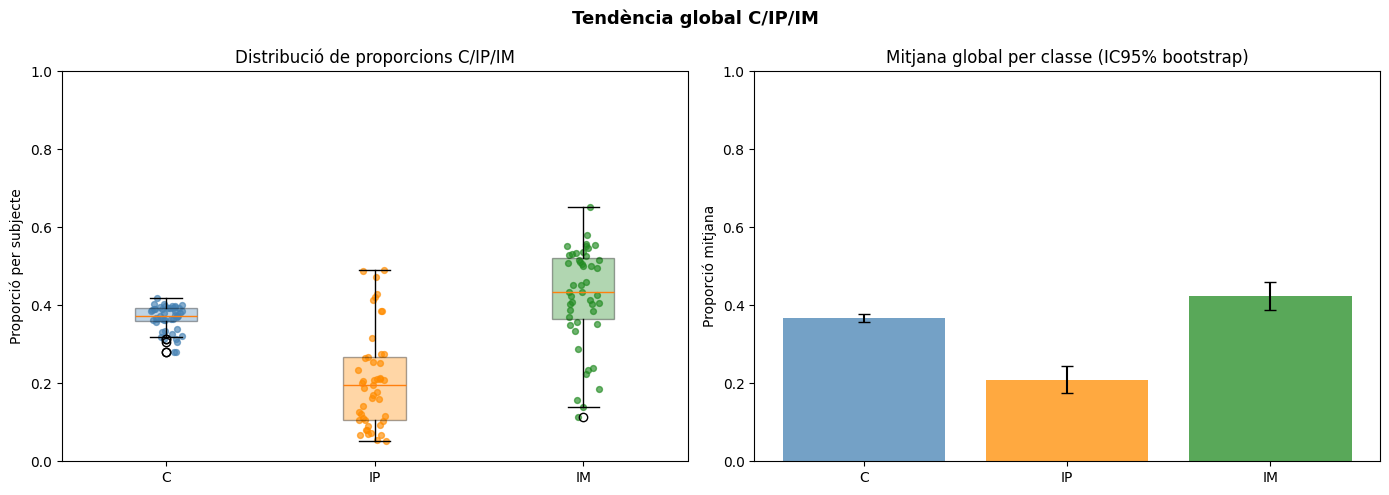

In [34]:
# Plot 2: distribució global entre subjectes (boxplot + mitjana amb IC95%)
prop_cols = [f"p_{cls}" for cls in CIPIM_CLASSES]
labels_cls = CIPIM_CLASSES
values = [df_cipim[c].dropna().values for c in prop_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (A) Boxplot + punts individuals
bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)
for patch, cls in zip(bp["boxes"], labels_cls):
    patch.set_facecolor(CIPIM_COLORS[cls])
    patch.set_alpha(0.35)

rng_local = np.random.default_rng(42)
for i, (cls, vals) in enumerate(zip(labels_cls, values), start=1):
    jitter = rng_local.uniform(-0.08, 0.08, size=len(vals))
    axes[0].scatter(np.full(len(vals), i) + jitter, vals, color=CIPIM_COLORS[cls], alpha=0.65, s=18)

axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Proporció per subjecte")
axes[0].set_title("Distribució de proporcions C/IP/IM")

# (B) Mitjana global + IC95% bootstrap
means = []
ci_low = []
ci_high = []
boot_n = 4000
for vals in values:
    vals = np.asarray(vals)
    means.append(vals.mean())
    boot = np.empty(boot_n)
    n = len(vals)
    for i in range(boot_n):
        idx = rng_local.integers(0, n, size=n)
        boot[i] = vals[idx].mean()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci_low.append(means[-1] - lo)
    ci_high.append(hi - means[-1])

x = np.arange(len(labels_cls))
axes[1].bar(x, means, color=[CIPIM_COLORS[c] for c in labels_cls], alpha=0.75)
axes[1].errorbar(x, means, yerr=[ci_low, ci_high], fmt="none", ecolor="black", capsize=4)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_cls)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Proporció mitjana")
axes[1].set_title("Mitjana global per classe (IC95% bootstrap)")

fig.suptitle("Tendència global C/IP/IM", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_global_distribucio_i_ic95.png", dpi=300, bbox_inches="tight")
plt.show()

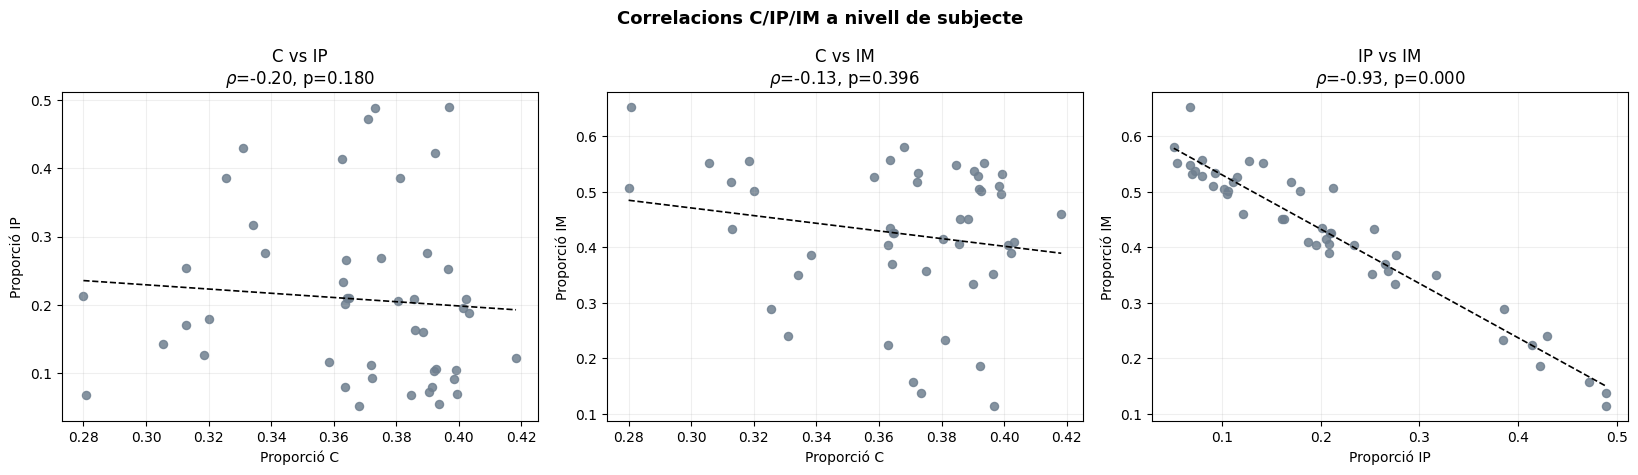

In [35]:
# Plot 3: correlacions a nivell de subjecte (scatter + Spearman)
corr_pairs = [
    ("p_C", "p_IP", "C", "IP"),
    ("p_C", "p_IM", "C", "IM"),
    ("p_IP", "p_IM", "IP", "IM"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharex=False, sharey=False)

for ax, (x_col, y_col, x_lab, y_lab) in zip(axes, corr_pairs):
    x_vals = df_cipim[x_col].values
    y_vals = df_cipim[y_col].values

    rho, p_val = spearmanr(x_vals, y_vals)

    ax.scatter(x_vals, y_vals, color="slategray", alpha=0.85, s=34)

    # Recta de tendència lineal només com a guia visual.
    m, b = np.polyfit(x_vals, y_vals, 1)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(x_line, m * x_line + b, color="black", linewidth=1.2, linestyle="--")

    ax.set_xlabel(f"Proporció {x_lab}")
    ax.set_ylabel(f"Proporció {y_lab}")
    ax.set_title(f"{x_lab} vs {y_lab}\n$\\rho$={rho:.2f}, p={p_val:.3f}")
    ax.grid(alpha=0.2)

fig.suptitle("Correlacions C/IP/IM a nivell de subjecte", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_nivell_subjecte_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

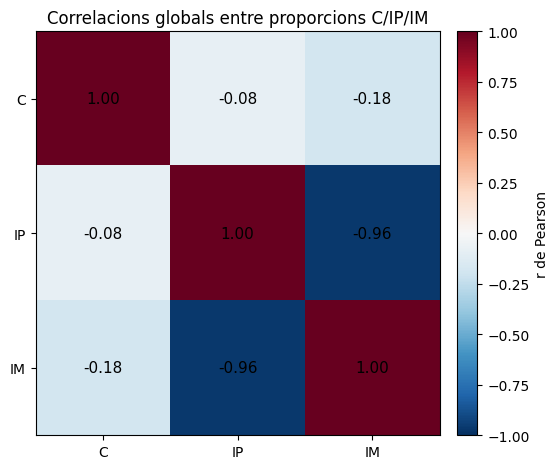

In [36]:
# Plot 4: matriu de correlacions entre proporcions C/IP/IM
corr_mat = df_cipim[["p_C", "p_IP", "p_IM"]].corr().values
labels = CIPIM_CLASSES

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(corr_mat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr_mat[i, j]:.2f}", ha="center", va="center", color="black", fontsize=11)

ax.set_title("Correlacions globals entre proporcions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="r de Pearson")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

### Mitjana harmònica i balanç de classes

Abans del Cohen's d, aquest bloc mostra com la **mitjana harmònica** captura el desbalanç entre C, IP i IM:
- baixa fort quan una classe és petita,
- queda propera als recomptes reals quan les 3 classes estan equilibrades.

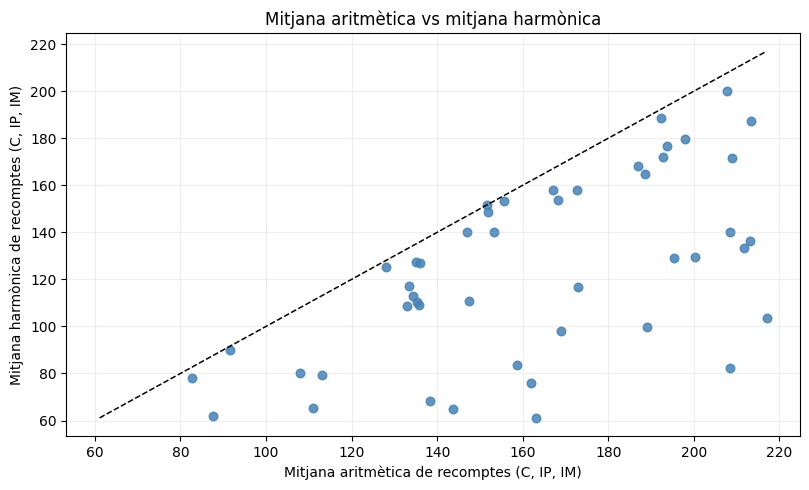

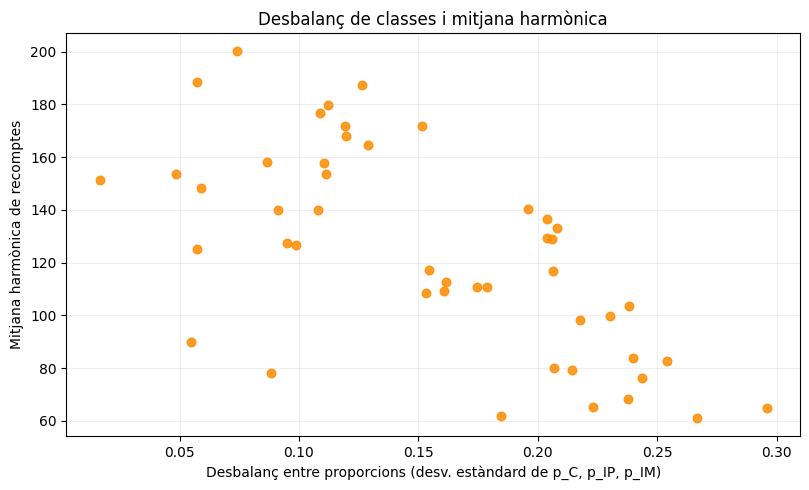

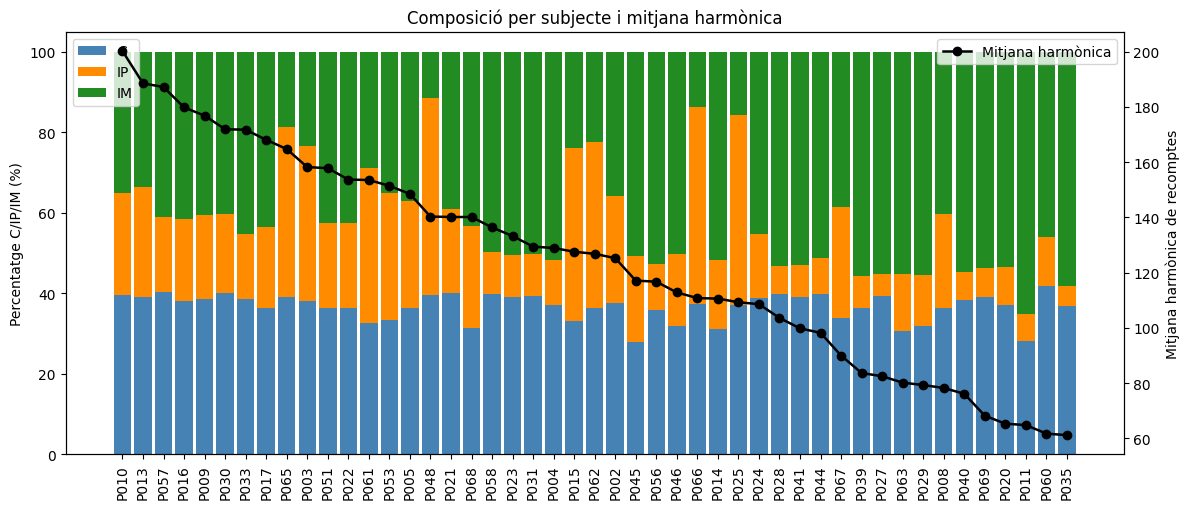

In [37]:
# Tres visualitzacions del concepte de mitjana harmònica sobre C/IP/IM

df_hm = df_cipim[["subjecte", "C", "IP", "IM", "p_C", "p_IP", "p_IM"]].copy()
df_hm["n_harm_3classes"] = 3.0 / ((1.0 / df_hm["C"]) + (1.0 / df_hm["IP"]) + (1.0 / df_hm["IM"]))
df_hm["n_arit_3classes"] = (df_hm["C"] + df_hm["IP"] + df_hm["IM"]) / 3.0
df_hm["balance_index"] = df_hm[["p_C", "p_IP", "p_IM"]].std(axis=1)

# Plot 1: mitjana aritmètica vs harmònica per subjecte
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["n_arit_3classes"], df_hm["n_harm_3classes"], color="steelblue", s=38, alpha=0.85)
xy_min = min(df_hm["n_arit_3classes"].min(), df_hm["n_harm_3classes"].min())
xy_max = max(df_hm["n_arit_3classes"].max(), df_hm["n_harm_3classes"].max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], linestyle="--", linewidth=1.1, color="black")
ax.set_xlabel("Mitjana aritmètica de recomptes (C, IP, IM)")
ax.set_ylabel("Mitjana harmònica de recomptes (C, IP, IM)")
ax.set_title("Mitjana aritmètica vs mitjana harmònica")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mitjana_aritmetica_vs_harmonica_c_ip_im.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: desbalanç de proporcions vs mitjana harmònica
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["balance_index"], df_hm["n_harm_3classes"], color="darkorange", s=38, alpha=0.85)
ax.set_xlabel("Desbalanç entre proporcions (desv. estàndard de p_C, p_IP, p_IM)")
ax.set_ylabel("Mitjana harmònica de recomptes")
ax.set_title("Desbalanç de classes i mitjana harmònica")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "desbalanc_proporcions_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: proporcions apilades, ordenades per mitjana harmònica
plot_df = df_hm.sort_values("n_harm_3classes", ascending=False).reset_index(drop=True)
subjectes_hm = plot_df["subjecte"].tolist()
x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 5.2))
for cls in ["C", "IP", "IM"]:
    vals = plot_df[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax2 = ax.twinx()
ax2.plot(x, plot_df["n_harm_3classes"].values, color="black", linewidth=1.8, marker="o", label="Mitjana harmònica")
ax2.set_ylabel("Mitjana harmònica de recomptes")

ax.set_xticks(x)
ax.set_xticklabels(subjectes_hm, rotation=90)
ax.set_ylabel("Percentatge C/IP/IM (%)")
ax.set_title("Composició per subjecte i mitjana harmònica")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "composicio_i_mitjana_harmonica_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

### Efecte per subjecte: Cohen's d real (theta FCz i alpha Oz)

Aquí calculem **Cohen's d real** per subjecte sobre una variable contínua, en el contrast **Incongruent (I = IP+IM) vs Congruent (C)**:
$$
d = \frac{\bar{x}_I - \bar{x}_C}{s_{pooled}}
$$

Definicions d'aquest bloc:
- **Theta**: potència de banda 5–7 Hz a **FCz**.
- **Alpha**: potència de banda 8–12 Hz a **Oz**.
- Resum trial-a-trial a la finestra temporal $[0.5, 1.0]$ s.

Sobre undersampling per a Cohen's d:
- recomanat com a anàlisi principal: **no** (mantenir totes les dades),
- recomanat com a sensibilitat: **sí** (comparar amb versió balancejada).

In [38]:
COHENS_TABLE_PATH = TABLES_DIR / "cohens_d_real_per_subjecte.csv"

try:
    df_cohens = pd.read_csv(COHENS_TABLE_PATH)
    print(f"Taula carregada: {COHENS_TABLE_PATH}")
except Exception:
    print("Calculant Cohen's d per subjecte...")

    def trial_bandpower_mean(epochs_obj, channel, band, time_window):
        if channel not in epochs_obj.ch_names:
            return None
        data = epochs_obj.get_data(picks=[channel]).squeeze(axis=1)  # (n_trials, n_times)
        sfreq = epochs_obj.info["sfreq"]

        # Potencia de banda rapida: filtre temporal + potencia quadratica.
        filtered = mne.filter.filter_data(
            data,
            sfreq=sfreq,
            l_freq=band[0],
            h_freq=band[1],
            method="fir",
            verbose=False,
        )
        power = filtered**2
        tmask = (epochs_obj.times >= time_window[0]) & (epochs_obj.times <= time_window[1])
        return power[:, tmask].mean(axis=1)

    def cohens_d_independent(x_i, x_c):
        n_i = len(x_i)
        n_c = len(x_c)
        if n_i < 2 or n_c < 2:
            return np.nan

        s_i = float(np.std(x_i, ddof=1))
        s_c = float(np.std(x_c, ddof=1))
        pooled = np.sqrt(((n_i - 1) * (s_i**2) + (n_c - 1) * (s_c**2)) / (n_i + n_c - 2))
        if not np.isfinite(pooled) or pooled == 0:
            return np.nan

        return (float(np.mean(x_i)) - float(np.mean(x_c))) / pooled

    def cohens_d_undersampled(x_i, x_c, rng):
        n_min = min(len(x_i), len(x_c))
        if n_min < 2:
            return np.nan
        idx_i = rng.choice(len(x_i), size=n_min, replace=False)
        idx_c = rng.choice(len(x_c), size=n_min, replace=False)
        return cohens_d_independent(x_i[idx_i], x_c[idx_c])

    rows_d = []
    rng_us = np.random.default_rng(42)

    for fif_path in sorted(DATA_DIR.glob("*.fif")):
        subj = fif_path.stem
        ep = mne.read_epochs(fif_path, preload=False, verbose=False)

        c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
        i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]
        if len(c_names) == 0 or len(i_names) == 0:
            continue

        ep_c = ep[c_names].copy().load_data()
        ep_i = ep[i_names].copy().load_data()

        theta_c = trial_bandpower_mean(ep_c, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        theta_i = trial_bandpower_mean(ep_i, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        alpha_c = trial_bandpower_mean(ep_c, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)
        alpha_i = trial_bandpower_mean(ep_i, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)

        if theta_c is None or theta_i is None or alpha_c is None or alpha_i is None:
            continue

        d_theta_raw = cohens_d_independent(theta_i, theta_c)
        d_alpha_raw = cohens_d_independent(alpha_i, alpha_c)
        d_theta_us = cohens_d_undersampled(theta_i, theta_c, rng_us)
        d_alpha_us = cohens_d_undersampled(alpha_i, alpha_c, rng_us)

        row_ci = df_cipim[df_cipim["subjecte"] == subj]
        if row_ci.empty:
            continue

        c_count = float(row_ci["C"].iloc[0])
        ip_count = float(row_ci["IP"].iloc[0])
        im_count = float(row_ci["IM"].iloc[0])
        i_count = ip_count + im_count

        if min(c_count, ip_count, im_count) <= 0:
            n_harm = np.nan
        else:
            n_harm = 3.0 / ((1.0 / c_count) + (1.0 / ip_count) + (1.0 / im_count))

        n_balanced = 2.0 * min(c_count, i_count)

        rows_d.append(
            {
                "subjecte": subj,
                "cohens_d_theta_fcz": d_theta_raw,
                "cohens_d_alpha_oz": d_alpha_raw,
                "cohens_d_theta_fcz_us": d_theta_us,
                "cohens_d_alpha_oz_us": d_alpha_us,
                "n_C": len(theta_c),
                "n_I": len(theta_i),
                "n_harm_3classes": n_harm,
                "n_balanced_ci": n_balanced,
            }
        )

        del ep_c, ep_i, theta_c, theta_i, alpha_c, alpha_i
        gc.collect()

    df_cohens = pd.DataFrame(rows_d)
    if df_cohens.empty:
        raise RuntimeError("No s'ha pogut calcular cap Cohen's d per subjecte.")

    df_cohens.to_csv(COHENS_TABLE_PATH, index=False)
    print(f"Desada taula: {COHENS_TABLE_PATH}")

# Taules ordenades (mes gran -> mes petit)
df_theta_sorted = df_cohens.sort_values("cohens_d_theta_fcz", ascending=False).reset_index(drop=True)
df_alpha_sorted = df_cohens.sort_values("cohens_d_alpha_oz", ascending=False).reset_index(drop=True)

print("Cohen's d theta (FCz) ordenat de mes gran a mes petit:")
display(df_theta_sorted[["subjecte", "cohens_d_theta_fcz", "cohens_d_theta_fcz_us", "n_C", "n_I"]])

print("Cohen's d alpha (Oz) ordenat de mes gran a mes petit:")
display(df_alpha_sorted[["subjecte", "cohens_d_alpha_oz", "cohens_d_alpha_oz_us", "n_C", "n_I"]])

print("Extrems theta (maxim i minim):")
display(pd.concat([df_theta_sorted.head(1), df_theta_sorted.tail(1)], ignore_index=True))

print("Extrems alpha (maxim i minim):")
display(pd.concat([df_alpha_sorted.head(1), df_alpha_sorted.tail(1)], ignore_index=True))

Taula carregada: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_per_subjecte.csv
Cohen's d theta (FCz) ordenat de mes gran a mes petit:


,subjecte,cohens_d_theta_fcz,cohens_d_theta_fcz_us,n_C,n_I
0,P024,0.264917,0.349746,155,244
1,P045,0.182440,0.152445,112,288
2,P056,0.162061,0.203472,186,334
3,P023,0.156226,0.121656,249,388
4,P014,0.152215,0.030759,127,279
5,P033,0.139471,0.179162,242,385
6,P022,0.132587,0.149714,184,321
7,P008,0.117410,0.081831,90,158
8,P061,0.101966,0.036034,152,315
9,P040,0.087703,0.039793,187,299


Cohen's d alpha (Oz) ordenat de mes gran a mes petit:


,subjecte,cohens_d_alpha_oz,cohens_d_alpha_oz_us,n_C,n_I
0,P053,0.271332,0.336187,152,303
1,P008,0.136811,0.142572,90,158
2,P024,0.121339,0.110691,155,244
3,P010,0.120236,0.137200,247,376
4,P046,0.119875,0.092586,129,275
5,P004,0.116871,0.084701,218,368
6,P056,0.082881,0.034264,186,334
7,P013,0.052459,0.079843,225,352
8,P027,0.021755,-0.001287,246,379
9,P033,0.001810,0.003879,242,385


Extrems theta (maxim i minim):


,subjecte,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,n_C,n_I,n_harm_3classes,n_balanced_ci
0,P024,0.264917,0.121339,0.349746,0.110691,155,244,108.569112,310.0
1,P003,-0.243372,-0.519919,-0.238873,-0.517084,191,310,158.194826,382.0


Extrems alpha (maxim i minim):


,subjecte,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,n_C,n_I,n_harm_3classes,n_balanced_ci
0,P053,-0.048292,0.271332,-0.180135,0.336187,152,303,151.418030,304.0
1,P029,0.045724,-0.592646,0.076639,-0.488817,108,231,79.293291,216.0


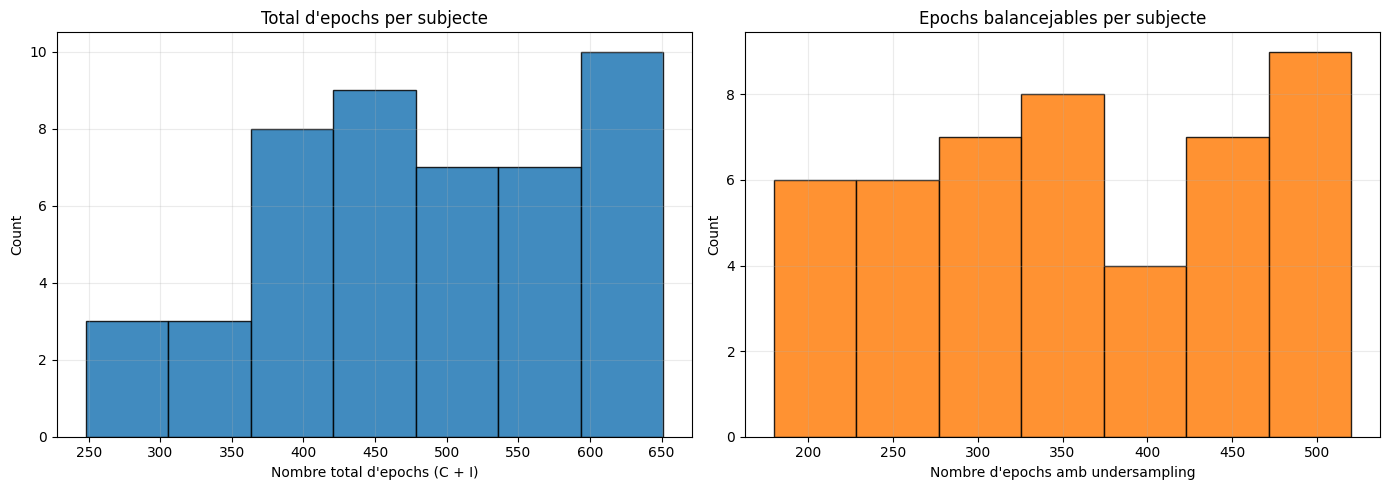

Resum ràpid:
- Total epochs per subjecte: min=248, max=651, mitjana=486.4
- 2×min(C, I): min=180, max=520, mitjana=360.5


In [ ]:
# Histogrames de disponibilitat d'epochs per subjecte
if "df_cohens" not in globals():
    raise RuntimeError("df_cohens no està disponible; executa primer la cel·la anterior.")

if "df_cipim" not in globals():
    raise RuntimeError("df_cipim no està disponible; executa primer la cel·la anterior.")

# 1) Nombre total d'epochs per subjecte
#    Aquí comptem totes les mostres disponibles per subjecte (C + I).
df_epochs_subjecte = df_cohens.copy()
df_epochs_subjecte["n_total_epochs"] = df_epochs_subjecte["n_C"] + df_epochs_subjecte["n_I"]

# 2) Nombre d'epochs balancejables per subjecte: 2 * min(C, I)
#    És el màxim que es podria usar si vols balancejar perfectament les classes.
df_balanceig = df_epochs_subjecte.copy()
df_balanceig["n_balancejable"] = 2 * np.minimum(df_balanceig["n_C"], df_balanceig["n_I"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma 1: total d'epochs per subjecte
axes[0].hist(df_epochs_subjecte["n_total_epochs"], bins=10, color="tab:blue", edgecolor="black", alpha=0.85)
axes[0].set_title("Total d'epochs per subjecte")
axes[0].set_xlabel("Nombre total d'epochs")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.25)

# Histograma 2: 2 * min(C, I)
axes[1].hist(df_balanceig["n_balancejable"], bins=10, color="tab:orange", edgecolor="black", alpha=0.85)
axes[1].set_title("Epochs balancejables per subjecte")
axes[1].set_xlabel("Nombre d'epochs amb undersampling")
axes[1].set_ylabel("Count")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Resum ràpid:")
print(
    f"- Total epochs per subjecte: min={df_epochs_subjecte['n_total_epochs'].min():.0f}, max={df_epochs_subjecte['n_total_epochs'].max():.0f}, mitjana={df_epochs_subjecte['n_total_epochs'].mean():.1f}"
)
print(
    f"- 2×min(C, I): min={df_balanceig['n_balancejable'].min():.0f}, max={df_balanceig['n_balancejable'].max():.0f}, mitjana={df_balanceig['n_balancejable'].mean():.1f}"
)

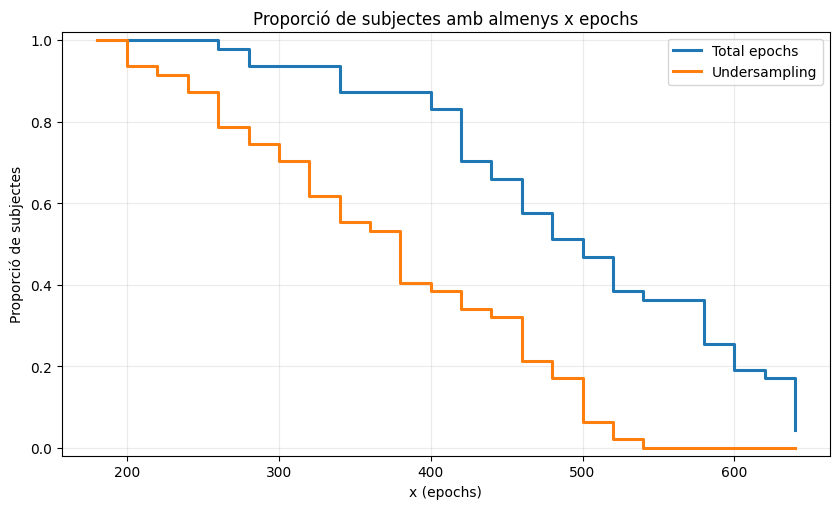

>= 200 epochs -> total: 100.0% | undersampling: 93.6%
>= 250 epochs -> total: 97.9% | undersampling: 83.0%
>= 300 epochs -> total: 93.6% | undersampling: 70.2%
>= 350 epochs -> total: 87.2% | undersampling: 53.2%
>= 400 epochs -> total: 83.0% | undersampling: 38.3%
>= 450 epochs -> total: 61.7% | undersampling: 25.5%
>= 500 epochs -> total: 46.8% | undersampling: 6.4%
>= 550 epochs -> total: 36.2% | undersampling: 0.0%
>= 600 epochs -> total: 19.1% | undersampling: 0.0%


In [65]:
# Plot germà: proporció de subjectes amb >= x epochs
vals_total = df_epochs_subjecte["n_total_epochs"].to_numpy(dtype=float)
vals_us = df_balanceig["n_balancejable"].to_numpy(dtype=float)

x_min = int(min(vals_total.min(), vals_us.min()))
x_max = int(max(vals_total.max(), vals_us.max()))
# Pas de 10 epochs per mantenir el gràfic net i interpretable
x_grid = np.arange(x_min, x_max + 1, 20)

prop_total = np.array([(vals_total >= x).mean() for x in x_grid], dtype=float)
prop_us = np.array([(vals_us >= x).mean() for x in x_grid], dtype=float)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.step(x_grid, prop_total, where="post", color="tab:blue", linewidth=2.2, label="Total epochs")
ax.step(x_grid, prop_us, where="post", color="tab:orange", linewidth=2.2, label="Undersampling")

ax.set_title("Proporció de subjectes amb almenys x epochs")
ax.set_xlabel("x (epochs)")
ax.set_ylabel("Proporció de subjectes")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Petit resum numèric en alguns llindars clau
for x in range(200, 601, 50):
    p_total = (vals_total >= x).mean()
    p_us = (vals_us >= x).mean()
    print(f">= {x:3d} epochs -> total: {p_total:.1%} | undersampling: {p_us:.1%}")

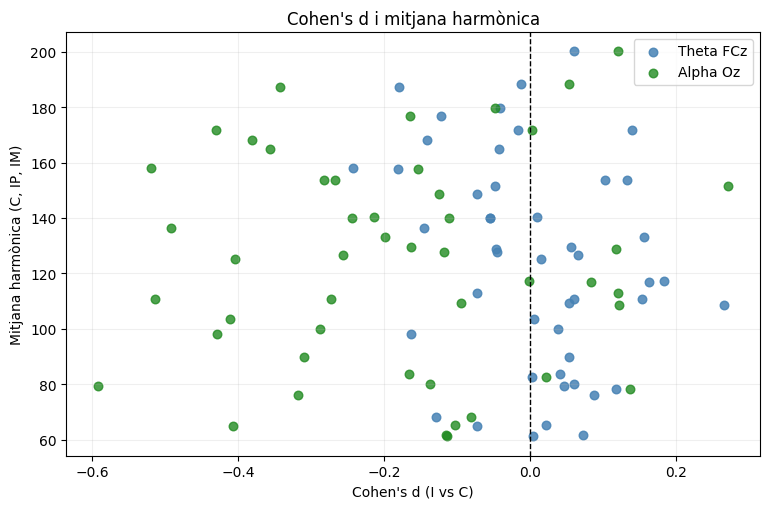

In [40]:
# x = Cohen's d, y = mitjana harmònica
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_harm_3classes"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_harm_3classes"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (I vs C)")
ax.set_ylabel("Mitjana harmònica (C, IP, IM)")
ax.set_title("Cohen's d i mitjana harmònica")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

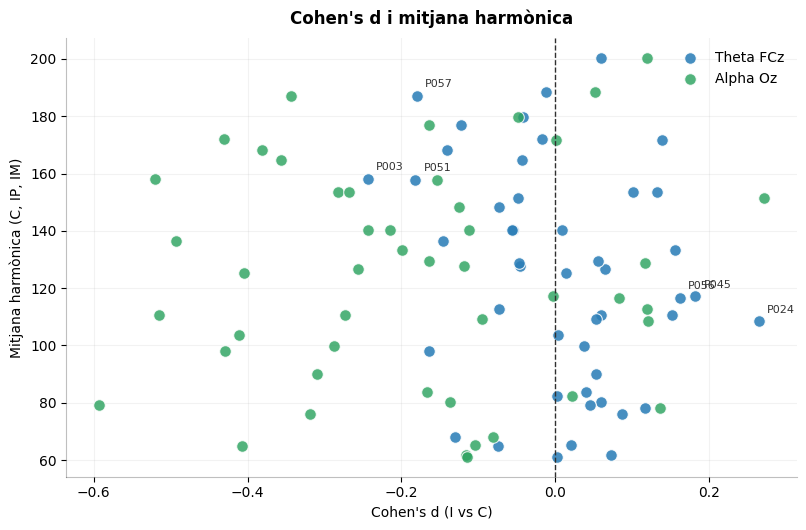

In [41]:
fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    df_plot["cohens_d_theta_fcz"],
    df_plot["n_harm_3classes"],
    s=70,
    color="#2C7FB8",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Theta FCz",
)

ax.scatter(
    df_plot["cohens_d_alpha_oz"],
    df_plot["n_harm_3classes"],
    s=70,
    color="#2CA25F",
    alpha=0.82,
    edgecolor="white",
    linewidth=0.8,
    label="Alpha Oz",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Cohen's d (I vs C)")
ax.set_ylabel("Mitjana harmònica (C, IP, IM)")
ax.set_title("Cohen's d i mitjana harmònica", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

# Opcional: anotar els 3 extrems més grans i més petits
top3 = df_plot.nlargest(3, "cohens_d_theta_fcz")
bottom3 = df_plot.nsmallest(3, "cohens_d_theta_fcz")

for _, r in pd.concat([top3, bottom3]).iterrows():
    ax.annotate(
        r["subjecte"],
        (r["cohens_d_theta_fcz"], r["n_harm_3classes"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
        color="#333333",
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mitjana_harmonica_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

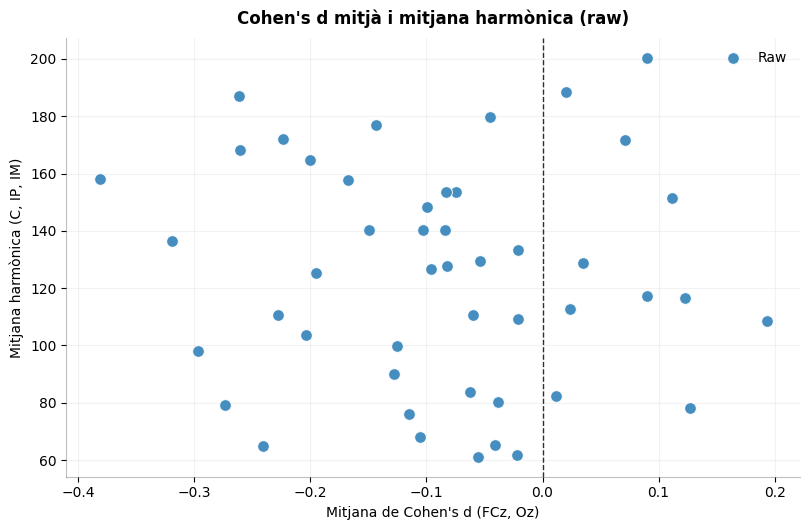

In [42]:
# Plot similar: Cohen's d mitjà (FCz + Oz) vs mida harmònica, només raw
mean_raw = 0.5 * (df_cohens["cohens_d_theta_fcz"] + df_cohens["cohens_d_alpha_oz"])

fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    mean_raw,
    df_cohens["n_harm_3classes"],
    s=72,
    color="#2C7FB8",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Raw",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Mitjana de Cohen's d (FCz, Oz)")
ax.set_ylabel("Mitjana harmònica (C, IP, IM)")
ax.set_title("Cohen's d mitjà i mitjana harmònica (raw)", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_mean_raw_vs_mitjana_harmonica_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

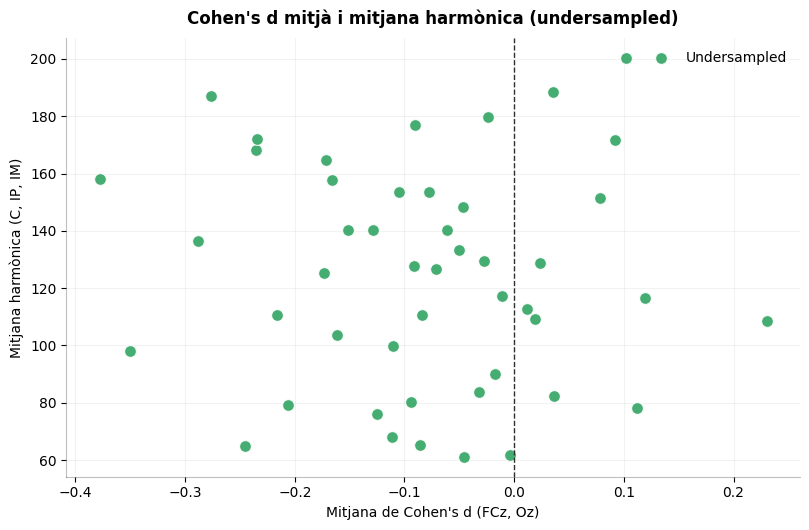

In [43]:
# Plot similar: Cohen's d mitjà (FCz + Oz) vs mida harmònica, només undersampled
mean_us = 0.5 * (df_cohens["cohens_d_theta_fcz_us"] + df_cohens["cohens_d_alpha_oz_us"])

fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    mean_us,
    df_cohens["n_harm_3classes"],
    s=72,
    color="#2CA25F",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Undersampled",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Mitjana de Cohen's d (FCz, Oz)")
ax.set_ylabel("Mitjana harmònica (C, IP, IM)")
ax.set_title("Cohen's d mitjà i mitjana harmònica (undersampled)", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_mean_undersampled_vs_mitjana_harmonica_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

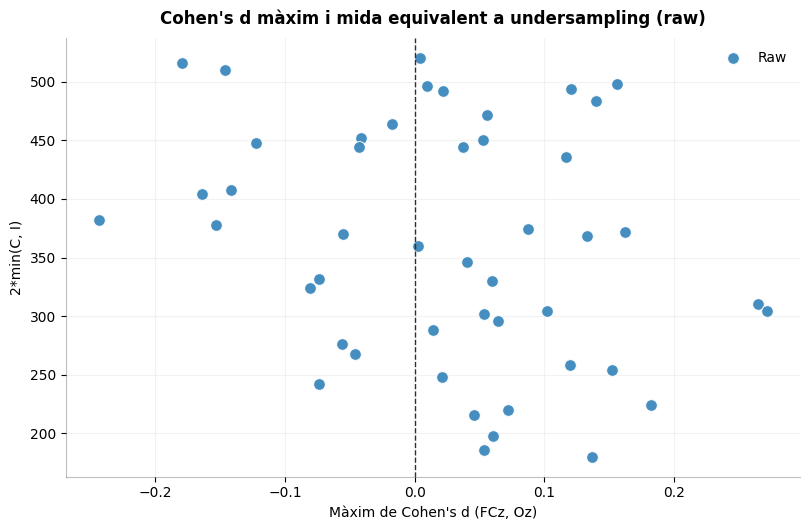

In [44]:
# Plot similar: Cohen's d màxim (FCz, Oz) vs mida balanced CI, només raw
max_raw = np.maximum(df_cohens["cohens_d_theta_fcz"], df_cohens["cohens_d_alpha_oz"])

fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    max_raw,
    df_cohens["n_balanced_ci"],
    s=72,
    color="#2C7FB8",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Raw",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Màxim de Cohen's d (FCz, Oz)")
ax.set_ylabel("2*min(C, I)")
ax.set_title("Cohen's d màxim i mida equivalent a undersampling (raw)", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_max_raw_vs_mida_undersampling_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

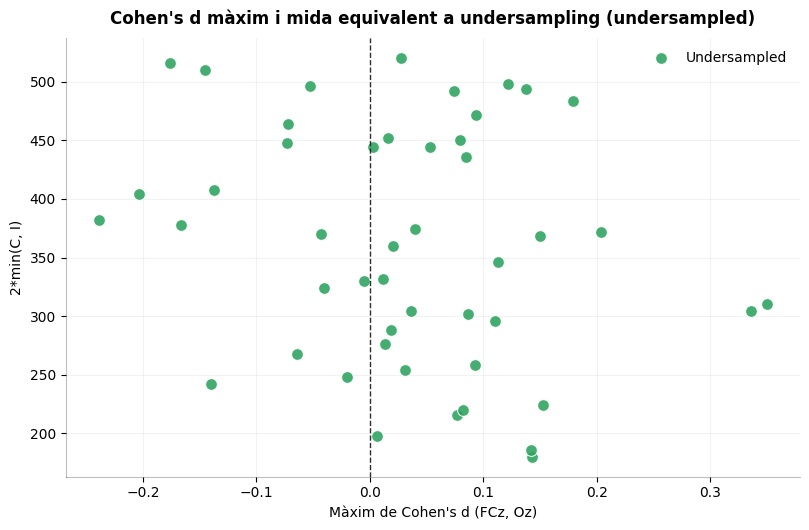

In [45]:
# Plot similar: Cohen's d màxim (FCz, Oz) vs mida balanced CI, només undersampled
max_us = np.maximum(df_cohens["cohens_d_theta_fcz_us"], df_cohens["cohens_d_alpha_oz_us"])

fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    max_us,
    df_cohens["n_balanced_ci"],
    s=72,
    color="#2CA25F",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Undersampled",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Màxim de Cohen's d (FCz, Oz)")
ax.set_ylabel("2*min(C, I)")
ax.set_title("Cohen's d màxim i mida equivalent a undersampling (undersampled)", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_max_undersampled_vs_mida_undersampling_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

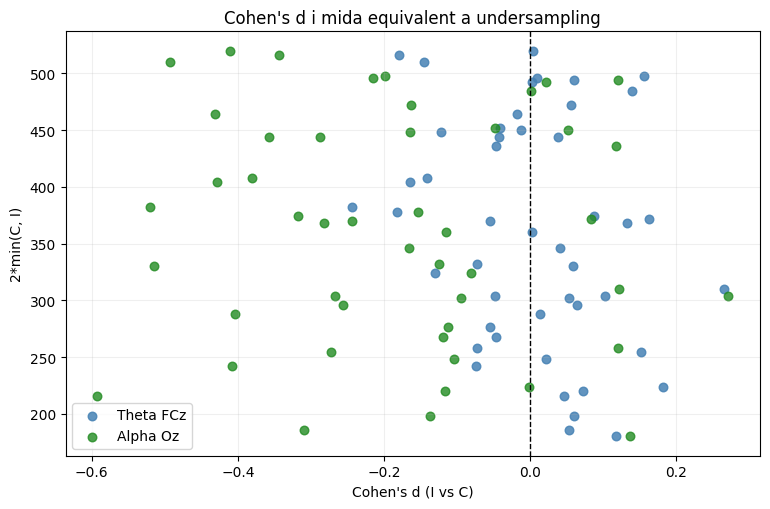

In [46]:
# x = Cohen's d, y = mida equivalent a undersampling
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_balanced_ci"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_balanced_ci"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (I vs C)")
ax.set_ylabel("2*min(C, I)")
ax.set_title("Cohen's d i mida equivalent a undersampling")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mida_undersampling.png", dpi=300, bbox_inches="tight")
plt.show()

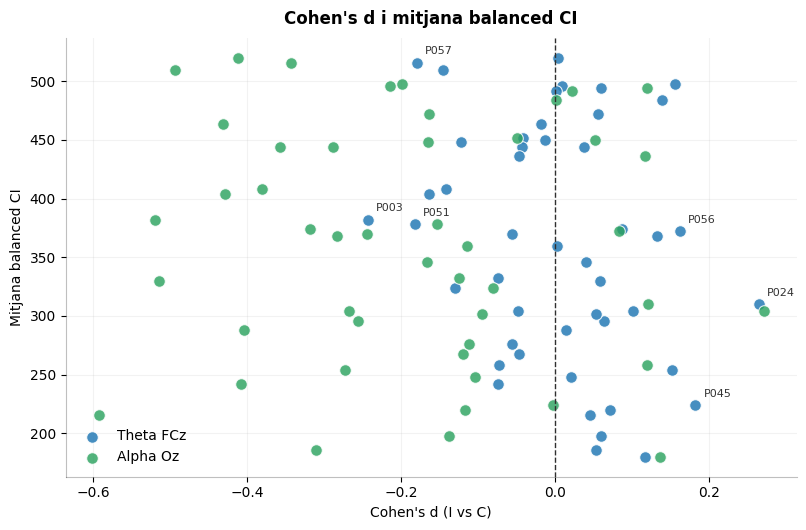

In [47]:
fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.scatter(
    df_plot["cohens_d_theta_fcz"],
    df_plot["n_balanced_ci"],
    s=70,
    color="#2C7FB8",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    label="Theta FCz",
)

ax.scatter(
    df_plot["cohens_d_alpha_oz"],
    df_plot["n_balanced_ci"],
    s=70,
    color="#2CA25F",
    alpha=0.82,
    edgecolor="white",
    linewidth=0.8,
    label="Alpha Oz",
)

ax.axvline(0, color="#2f2f2f", linestyle="--", linewidth=1)
ax.grid(alpha=0.16, linewidth=0.8)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

ax.set_xlabel("Cohen's d (I vs C)")
ax.set_ylabel("Mitjana balanced CI")
ax.set_title("Cohen's d i mitjana balanced CI", pad=10, fontweight="semibold")
ax.legend(frameon=False, loc="best")

# Opcional: anotar els 3 extrems més grans i més petits
top3 = df_plot.nlargest(3, "cohens_d_theta_fcz")
bottom3 = df_plot.nsmallest(3, "cohens_d_theta_fcz")

for _, r in pd.concat([top3, bottom3]).iterrows():
    ax.annotate(
        r["subjecte"],
        (r["cohens_d_theta_fcz"], r["n_balanced_ci"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
        color="#333333",
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mitjana_balanced_ci_aesthetic.png", dpi=300, bbox_inches="tight")
plt.show()

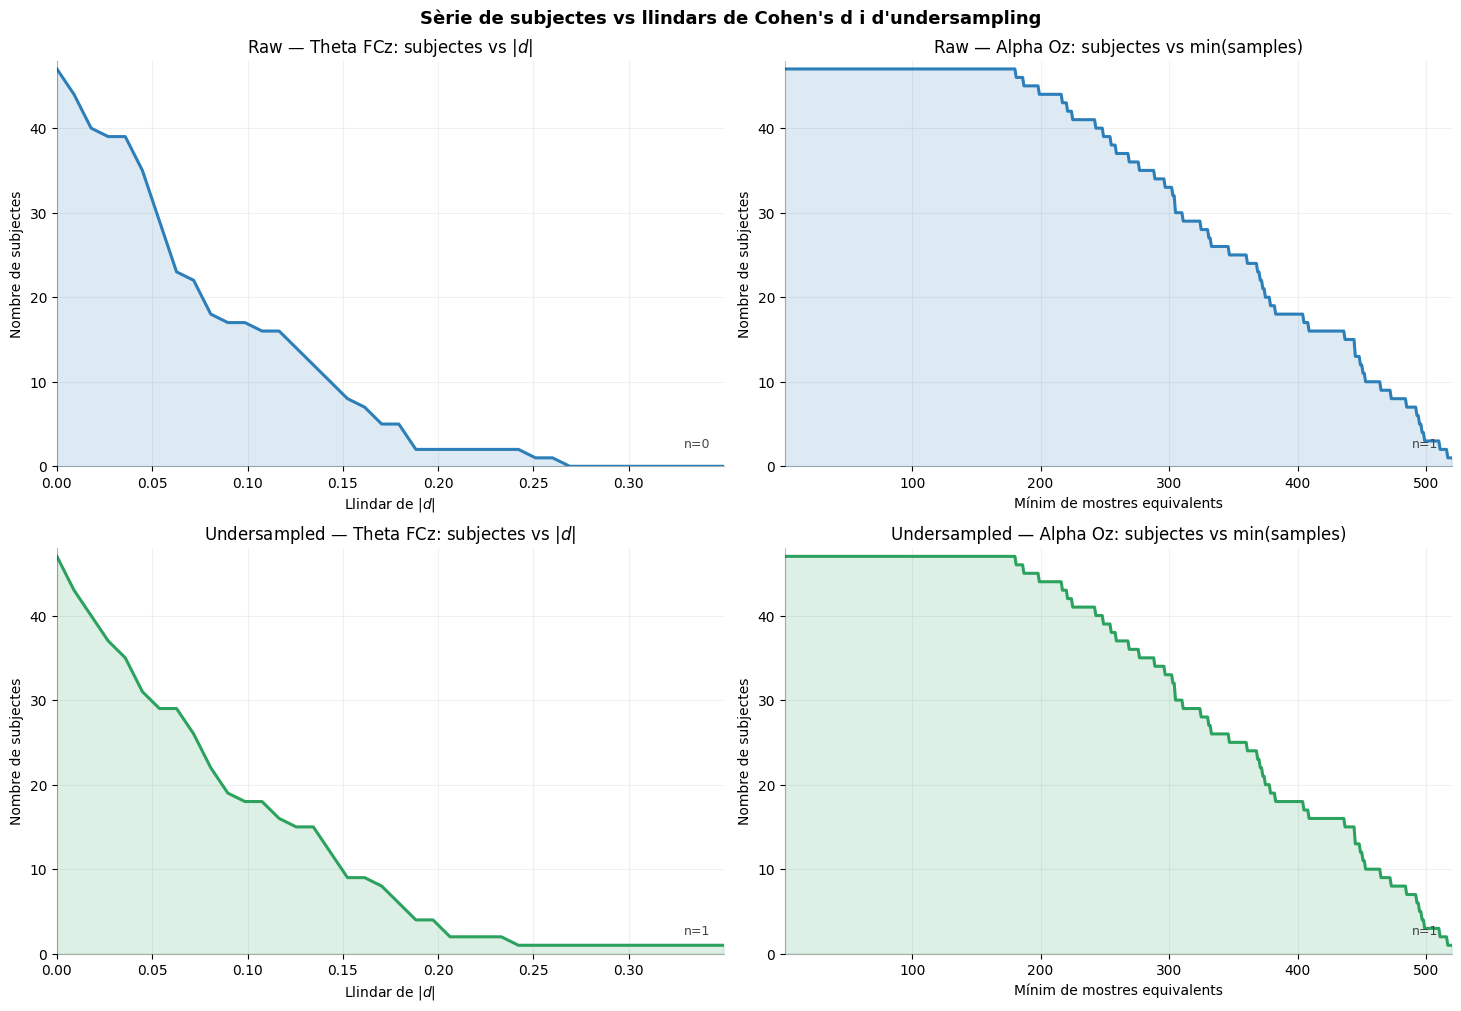

In [48]:
# Sèrie de plots: nombre de subjectes en funció del llindar de Cohen's d i del mínim de mostres
# Farem un grid 2x2 amb un bucle imbricat: files = raw/undersampled, columnes = |d| i min(samples)

series_specs = [
    (
        "raw",
        {
            "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        },
    ),
    (
        "undersampled",
        {
            "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        },
    ),
]

sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_limits = {
    "theta": float(np.nanmax(df_cohens[["cohens_d_theta_fcz", "cohens_d_theta_fcz_us"]].abs().to_numpy())),
    "alpha": float(np.nanmax(df_cohens[["cohens_d_alpha_oz", "cohens_d_alpha_oz_us"]].abs().to_numpy())),
}
d_thresholds = {key: np.linspace(0.0, max(value, 1e-6), 40) for key, value in d_limits.items()}
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 10), constrained_layout=True)
panel_info = [("theta", "Theta FCz"), ("alpha", "Alpha Oz")]
row_colors = {"raw": "#2C7FB8", "undersampled": "#2CA25F"}
row_titles = {"raw": "Raw", "undersampled": "Undersampled"}

for row_idx, (row_key, values_by_band) in enumerate(series_specs):
    for col_idx, (band_key, band_label) in enumerate(panel_info):
        ax = axes[row_idx, col_idx]
        values = values_by_band[band_key]
        color = row_colors[row_key]

        if col_idx == 0:
            thresholds = d_thresholds[band_key]
            counts = np.array([(values >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel(r"Llindar de $|d|$")
            ax.set_ylabel("Nombre de subjectes")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjectes vs $|d|$")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)
        else:
            thresholds = sample_thresholds
            counts = np.array([(sample_counts >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel("Mínim de mostres equivalents")
            ax.set_ylabel("Nombre de subjectes")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjectes vs min(samples)")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)

        ax.grid(alpha=0.18, linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_alpha(0.25)
        ax.spines["bottom"].set_alpha(0.25)
        ax.text(
            0.98,
            0.04,
            f"n={counts[-1]:d}",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=9,
            color="#444444",
        )

fig.suptitle("Sèrie de subjectes vs llindars de Cohen's d i d'undersampling", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_subjectes_vs_llindars_nested_grid.png", dpi=300, bbox_inches="tight")
plt.show()

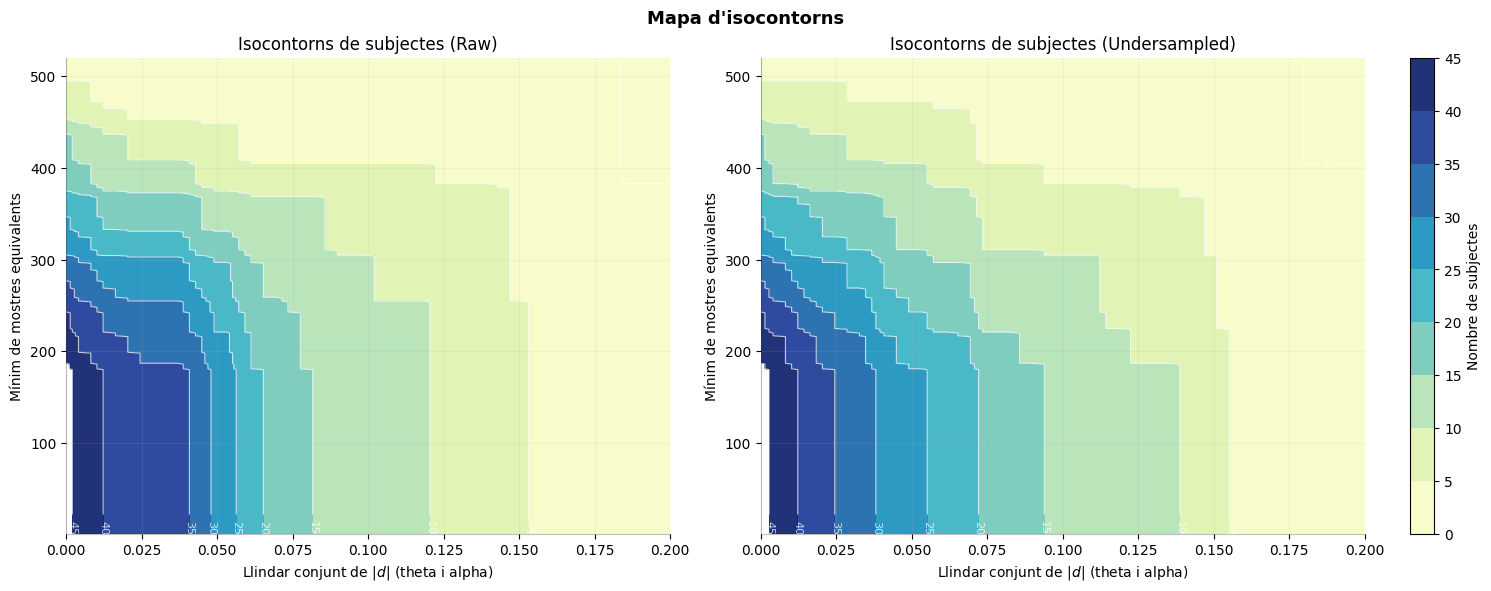

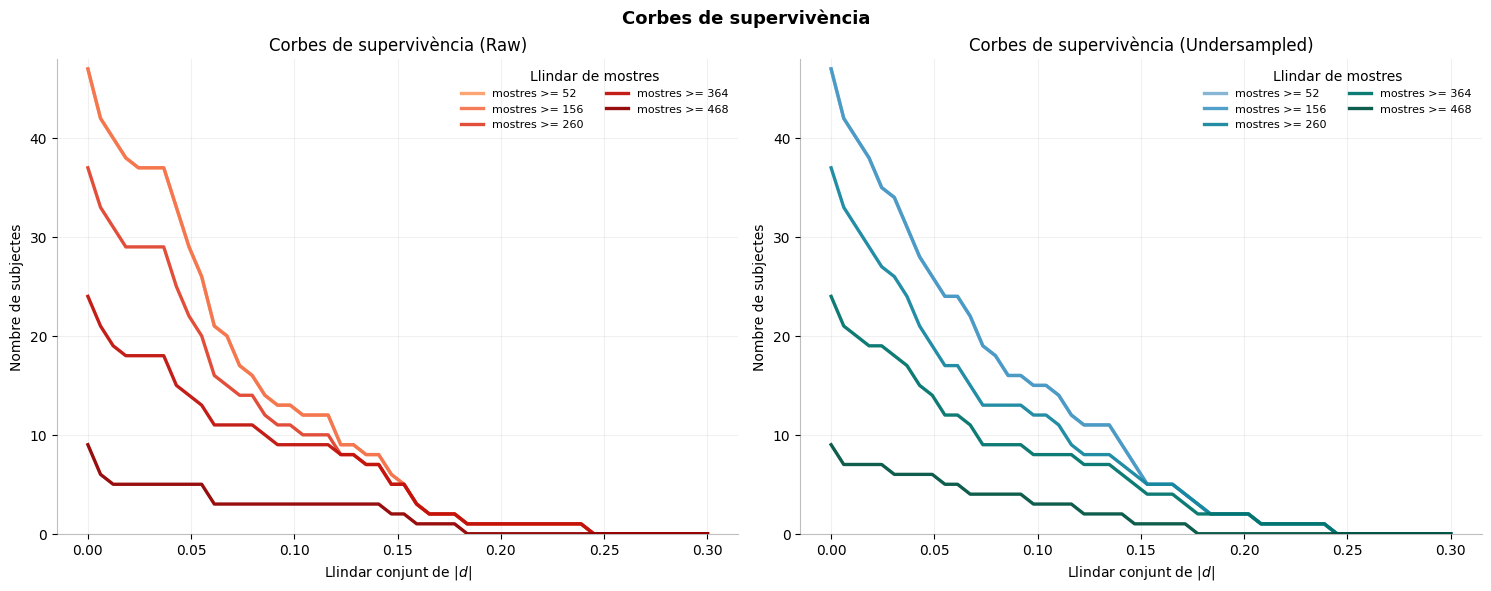

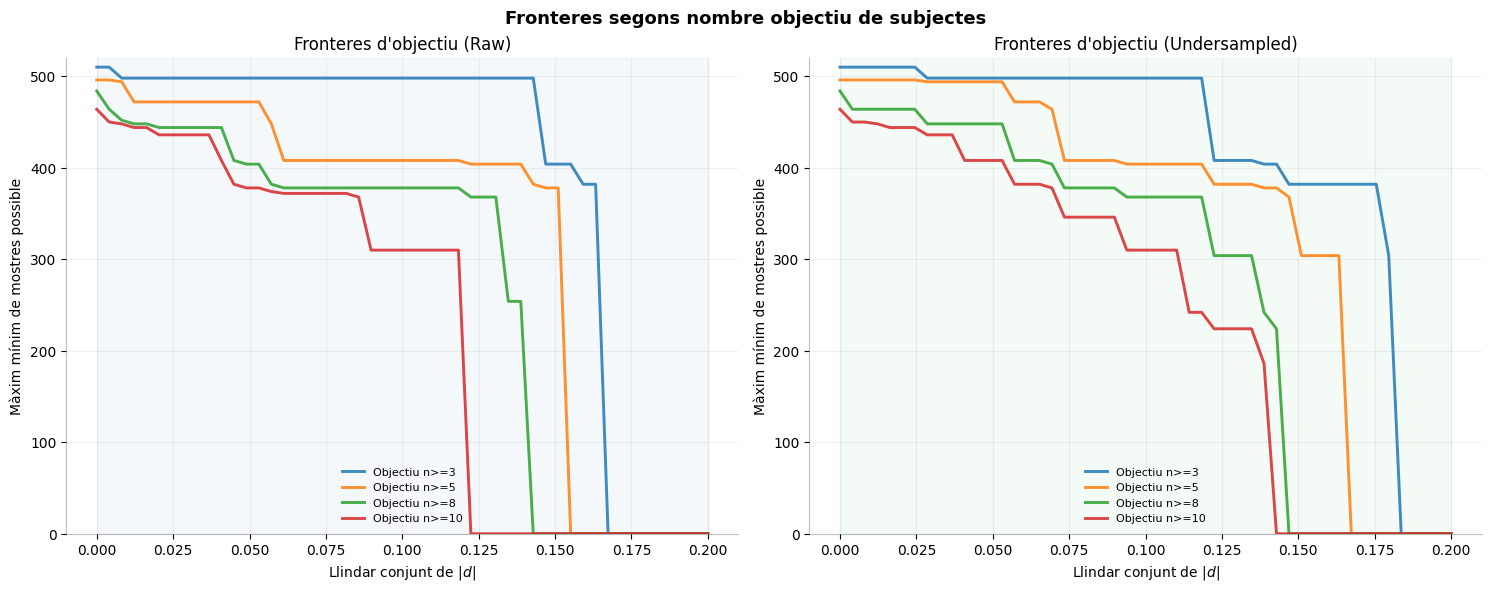

In [49]:
sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_thr_max = float(
    np.nanmax(
        df_cohens[
            [
                "cohens_d_theta_fcz",
                "cohens_d_alpha_oz",
                "cohens_d_theta_fcz_us",
                "cohens_d_alpha_oz_us",
            ]
        ]
        .abs()
        .to_numpy()
    )
)

# Topalls del llindar conjunt segons la petició:
# - Plots A i C fins a 0.2
# - Plot B fins a 0.3
# Els fixem explícitament per mantenir l'escala estable entre execucions.
d_thresholds_ac = np.linspace(0.0, 0.2, 50)
d_thresholds_b = np.linspace(0.0, 0.3, 50)

sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

specs = {
    "Raw": {
        "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        "color": "#2C7FB8",
    },
    "Undersampled": {
        "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        "color": "#2CA25F",
    },
}


def build_grid(theta_vals, alpha_vals, d_thresholds):
    grid = np.zeros((len(sample_thresholds), len(d_thresholds)), dtype=int)
    for i, n_thr in enumerate(sample_thresholds):
        for j, d_thr in enumerate(d_thresholds):
            keep = (theta_vals >= d_thr) & (alpha_vals >= d_thr) & (sample_counts >= n_thr)
            grid[i, j] = int(keep.sum())
    return grid


grid_by_name_a = {name: build_grid(vals["theta"], vals["alpha"], d_thresholds_ac) for name, vals in specs.items()}
grid_by_name_b = {name: build_grid(vals["theta"], vals["alpha"], d_thresholds_b) for name, vals in specs.items()}

# --- Plot A: Isocontorns suaus (raw vs undersampled) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)
for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name_a[name]
    levels = np.arange(0, len(df_cohens) + 1, max(1, len(df_cohens) // 8))

    cf = ax.contourf(
        d_thresholds_ac,
        sample_thresholds,
        grid,
        levels=levels,
        cmap="YlGnBu",
        alpha=0.95,
    )
    c = ax.contour(
        d_thresholds_ac,
        sample_thresholds,
        grid,
        levels=levels,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(c, fmt="%d", fontsize=8)

    ax.set_title(f"Isocontorns de subjectes ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$ (theta i alpha)")
    ax.set_ylabel("Mínim de mostres equivalents")
    ax.grid(alpha=0.14)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
cbar.set_label("Nombre de subjectes")
fig.suptitle("Mapa d'isocontorns", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_isocontorns.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot B: Corbes de supervivència per nivells de mostres ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

# Paletes separades per millorar la visibilitat entre corbes i entre panells.
palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Aquests llindars són de MOSTRES EQUIVALENTS (n_balanced_ci), no de subjectes.
    q_levels = np.quantile(sample_thresholds, [0.1, 0.3, 0.5, 0.7, 0.9]).astype(int)
    q_levels = np.unique(np.clip(q_levels, sample_thresholds.min(), sample_thresholds.max()))
    palette = palette_by_name[name]

    for k, n_thr in enumerate(q_levels):
        counts = []
        for d_thr in d_thresholds_b:
            keep = (vals["theta"] >= d_thr) & (vals["alpha"] >= d_thr) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            d_thresholds_b,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"mostres >= {n_thr}",
        )

    ax.set_title(f"Corbes de supervivència ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$")
    ax.set_ylabel("Nombre de subjectes")
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Llindar de mostres")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Corbes de supervivència", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot C: Fronteres per objectiu de subjectes (n-target) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

n_targets = [3, 5, 8, 10]
n_targets = [n for n in n_targets if n <= len(df_cohens)]
if len(n_targets) == 0:
    n_targets = [max(1, len(df_cohens) // 2)]

for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name_a[name]
    color = vals["color"]

    for t_idx, target_n in enumerate(n_targets):
        frontier = []
        for j in range(len(d_thresholds_ac)):
            col = grid[:, j]
            rows_ok = np.where(col >= target_n)[0]
            if len(rows_ok) == 0:
                frontier.append(0)
            else:
                frontier.append(sample_thresholds[rows_ok.max()])

        ax.plot(
            d_thresholds_ac,
            frontier,
            linewidth=2.1,
            alpha=0.85,
            label=f"Objectiu n>={target_n}",
        )

    ax.fill_between(d_thresholds_ac, 0, np.nanmax(sample_thresholds), color=color, alpha=0.05)
    ax.set_title(f"Fronteres d'objectiu ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$")
    ax.set_ylabel("Màxim mínim de mostres possible")
    ax.set_ylim(0, sample_thresholds.max())
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Fronteres segons nombre objectiu de subjectes", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu.png", dpi=300, bbox_inches="tight")
plt.show()

In [50]:
# Rànquing final de subjectes (undersampled): combina |d| theta, |d| alpha i mida mostral
def minmax_01(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    lo, hi = float(np.nanmin(s)), float(np.nanmax(s))
    if np.isclose(hi - lo, 0.0):
        return pd.Series(np.zeros(len(s), dtype=float), index=s.index)
    return (s - lo) / (hi - lo)


# Pots ajustar aquests pesos si vols prioritzar més efecte o més mida mostral.
W_EFFECT = 0.75
W_SIZE = 0.25
N_SELECT = min(10, len(df_cohens))

rank_df = df_cohens[["subjecte", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]].copy()
rank_df["d_theta_us_abs"] = rank_df["cohens_d_theta_fcz_us"].abs()
rank_df["d_alpha_us_abs"] = rank_df["cohens_d_alpha_oz_us"].abs()

# Efecte combinat: mitjana geomètrica perquè theta i alpha hagin de ser tots dos alts.
rank_df["d_combo_us"] = np.sqrt(rank_df["d_theta_us_abs"] * rank_df["d_alpha_us_abs"])
rank_df["d_combo_us_norm"] = minmax_01(rank_df["d_combo_us"])
rank_df["n_balanced_norm"] = minmax_01(rank_df["n_balanced_ci"])

rank_df["score_seleccio"] = W_EFFECT * rank_df["d_combo_us_norm"] + W_SIZE * rank_df["n_balanced_norm"]

rank_df = rank_df.sort_values("score_seleccio", ascending=False).reset_index(drop=True)

cols_show = [
    "subjecte",
    "d_theta_us_abs",
    "d_alpha_us_abs",
    "d_combo_us",
    "n_balanced_ci",
    "score_seleccio",
]

print("Top 10 subjectes")
display(
    rank_df.head(10)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

print("Pitjors 5 subjectes")
display(
    rank_df.tail(5)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

Top 10 subjectes


subjecte,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P003,0.239,0.517,0.351,382.0,0.899
P044,0.203,0.497,0.318,404.0,0.841
P057,0.177,0.376,0.258,516.0,0.791
P058,0.146,0.432,0.251,510.0,0.772
P017,0.137,0.333,0.214,408.0,0.616
P053,0.180,0.336,0.246,304.0,0.610
P022,0.150,0.305,0.214,368.0,0.586
P023,0.122,0.222,0.164,498.0,0.573
P030,0.073,0.397,0.170,464.0,0.560
P011,0.140,0.351,0.222,242.0,0.511


Pitjors 5 subjectes


subjecte,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P066,0.005,0.427,0.048,330.0,0.195
P005,0.011,0.105,0.035,332.0,0.167
P020,0.020,0.150,0.055,248.0,0.150
P068,0.014,0.135,0.043,276.0,0.143
P063,0.006,0.194,0.034,198.0,0.067


In [51]:
# Selecció automàtica: 5 punts d'inflexió de la corba de supervivència
# Identifica transicions reals on canvia significativament la velocitat de caiguda de subjectes
# AMB SEPARABILITAT: punts distants entre ells

score_thresholds = np.linspace(0.0, 1.0, 101)

# Calcular utilitat per a cada llindar
utility_rows = []
for t in score_thresholds:
    sel = rank_df[rank_df["score_seleccio"] >= t]
    n_sel = int(len(sel))
    if n_sel == 0:
        mean_score = np.nan
        utility = np.nan
    else:
        mean_score = float(sel["score_seleccio"].mean())
        utility = float(np.sqrt(n_sel / len(rank_df)) * mean_score)
    utility_rows.append(
        {
            "llindar": float(t),
            "n_subjectes": n_sel,
            "frac_subjectes": n_sel / len(rank_df),
            "score_mitja": mean_score,
            "utility": utility,
        }
    )

df_utility = pd.DataFrame(utility_rows).dropna().sort_values("llindar").reset_index(drop=True)

# Per a cada llindar t, mostra quants subjectes tenen score >= t.
survival_counts = np.array([(rank_df["score_seleccio"] >= t).sum() for t in score_thresholds], dtype=int)

# Calcular derivada numèrica (canvi de N per pas de threshold)
diffs = np.diff(survival_counts)
abs_diffs = np.abs(diffs)

# Calcular "acceleració" (canvi de la derivada - on canvia la velocitat de caigda)
accel = np.diff(abs_diffs)

# Identificar punts on hi ha pics d'acceleració (transicions)
threshold_accel = np.percentile(accel, 80)  # Top 20% de canvis
inflection_indices = np.where(accel > threshold_accel)[0]

# Agrupar índexs propers (evitar duplicats)
if len(inflection_indices) > 0:
    inflection_points = []
    current_group = [inflection_indices[0]]
    for i in range(1, len(inflection_indices)):
        if inflection_indices[i] - inflection_indices[i - 1] <= 2:
            current_group.append(inflection_indices[i])
        else:
            inflection_points.append(int(np.mean(current_group)))
            current_group = [inflection_indices[i]]
    inflection_points.append(int(np.mean(current_group)))
else:
    inflection_points = []

# Convertir a índexs de df_utility
inflection_thresholds = []
for idx in inflection_points:
    if idx < len(score_thresholds):
        thr = score_thresholds[idx]
        # Buscar el llindar més proper a df_utility
        closest_idx = int((df_utility["llindar"] - thr).abs().idxmin())
        if closest_idx not in [x[0] for x in inflection_thresholds]:
            n_subj = int(df_utility.loc[closest_idx, "n_subjectes"])
            score_mean = float(df_utility.loc[closest_idx, "score_mitja"])
            utility_val = float(df_utility.loc[closest_idx, "utility"])
            inflection_thresholds.append((closest_idx, thr, n_subj, score_mean, utility_val))

# Ordenar per utilitat descendent
inflection_thresholds_sorted = sorted(inflection_thresholds, key=lambda x: x[4], reverse=True)

# Seleccionar 5 punts amb separabilitat mínima (distància mínima entre llindars: 0.12)
MIN_THRESHOLD_GAP = 0.12
selected_points = []
for idx, thr, n_subj, score_mean, util in inflection_thresholds_sorted:
    # Comprovar si aquest punt és prou allunyat dels ja seleccionats
    if len(selected_points) == 0:
        selected_points.append((idx, thr, n_subj, score_mean, util))
    else:
        min_gap_to_existing = min(abs(thr - sp[1]) for sp in selected_points)
        if min_gap_to_existing >= MIN_THRESHOLD_GAP:
            selected_points.append((idx, thr, n_subj, score_mean, util))
    if len(selected_points) == 5:
        break

# Si no tenim 5, relaxem el criteri
if len(selected_points) < 5:
    MIN_THRESHOLD_GAP = 0.08  # Relaxar a 0.08
    selected_points = []
    for idx, thr, n_subj, score_mean, util in inflection_thresholds_sorted:
        if len(selected_points) == 0:
            selected_points.append((idx, thr, n_subj, score_mean, util))
        else:
            min_gap_to_existing = min(abs(thr - sp[1]) for sp in selected_points)
            if min_gap_to_existing >= MIN_THRESHOLD_GAP:
                selected_points.append((idx, thr, n_subj, score_mean, util))
        if len(selected_points) == 5:
            break

# Convertir a DataFrame final
selected_indices = [sp[0] for sp in selected_points]
df_key = (
    df_utility.loc[selected_indices, ["llindar", "n_subjectes", "score_mitja", "utility"]]
    .sort_values("llindar")  # Ordenar per llindar creixent per millor visualització
    .reset_index(drop=True)
)

display(
    df_key.style.hide(axis="index").format(
        {
            "llindar": "{:.3f}",
            "n_subjectes": "{:d}",
            "score_mitja": "{:.3f}",
            "utility": "{:.3f}",
        }
    )
)

# Mostrar selecció top-10 i automàtica per referència
top_pairs = [
    (row["subjecte"], f"{row['score_seleccio']:.2f}")
    for _, row in rank_df.head(10)[["subjecte", "score_seleccio"]].iterrows()
]

auto_threshold = float(df_key.loc[0, "llindar"])  # Millor proposició per utilitat
auto_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][["subjecte", "score_seleccio"]]
auto_pairs = [(row["subjecte"], f"{row['score_seleccio']:.2f}") for _, row in auto_df.iterrows()]

print(f"Top-10 (Subj, score):")
print(top_pairs)
print(f"\nSelecció automàtica (Proposició 1, Subj, score) [{len(auto_pairs)}]:")
print(auto_pairs)

llindar,n_subjectes,score_mitja,utility
0.050,47,0.379,0.379
0.200,41,0.412,0.385
0.330,25,0.520,0.379
0.480,12,0.646,0.326
0.770,4,0.826,0.241


Top-10 (Subj, score):
[('P003', '0.90'), ('P044', '0.84'), ('P057', '0.79'), ('P058', '0.77'), ('P017', '0.62'), ('P053', '0.61'), ('P022', '0.59'), ('P023', '0.57'), ('P030', '0.56'), ('P011', '0.51')]

Selecció automàtica (Proposició 1, Subj, score) [47]:
[('P003', '0.90'), ('P044', '0.84'), ('P057', '0.79'), ('P058', '0.77'), ('P017', '0.62'), ('P053', '0.61'), ('P022', '0.59'), ('P023', '0.57'), ('P030', '0.56'), ('P011', '0.51'), ('P024', '0.51'), ('P051', '0.49'), ('P031', '0.45'), ('P028', '0.44'), ('P048', '0.44'), ('P041', '0.44'), ('P029', '0.43'), ('P062', '0.43'), ('P010', '0.42'), ('P039', '0.41'), ('P009', '0.37'), ('P045', '0.37'), ('P040', '0.36'), ('P021', '0.35'), ('P067', '0.33'), ('P056', '0.30'), ('P004', '0.29'), ('P061', '0.28'), ('P069', '0.27'), ('P033', '0.26'), ('P016', '0.25'), ('P002', '0.24'), ('P065', '0.24'), ('P015', '0.23'), ('P013', '0.23'), ('P027', '0.23'), ('P035', '0.22'), ('P008', '0.22'), ('P046', '0.21'), ('P025', '0.21'), ('P014', '0.20'), ('P

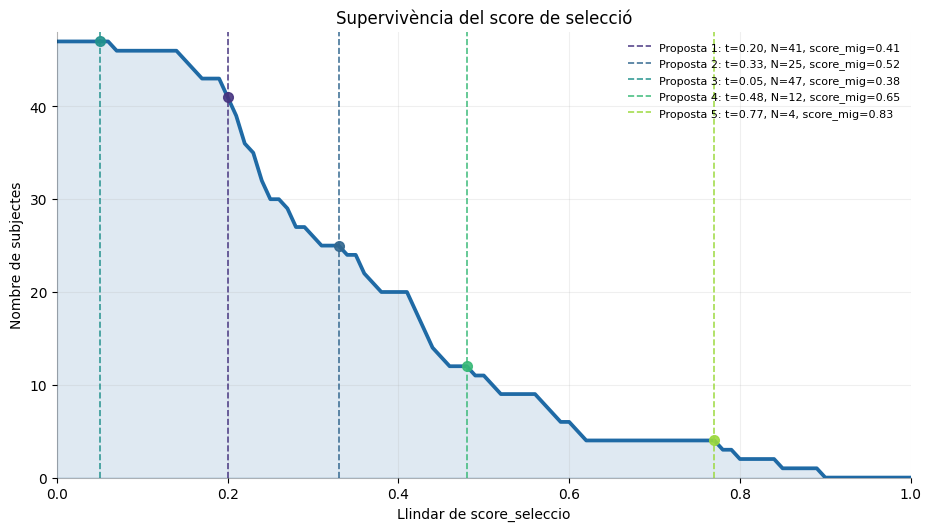

In [52]:
# Plot de supervivència del score de selecció amb llindars proposats

# Ordenem propostes per balanceig (utility): Proposta 1 = millor, ..., Proposta 5 = cinquena millor.
proposed_df = (
    df_key.sort_values("utility", ascending=False)
    .dropna(subset=["llindar"])
    .drop_duplicates(subset=["llindar"], keep="first")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
ax.plot(
    score_thresholds,
    survival_counts,
    color="#1f6aa5",
    linewidth=2.7,
)
ax.fill_between(score_thresholds, survival_counts, color="#1f6aa5", alpha=0.14)

th_colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(1, len(proposed_df))))
proposal_handles = []
proposal_labels = []
for i, (_, row) in enumerate(proposed_df.iterrows()):
    thr = float(row["llindar"])
    n_subj = int(row["n_subjectes"])
    score_mean = float(row["score_mitja"])

    # Línia vertical al llindar
    line = ax.axvline(
        thr,
        color=th_colors[i],
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    # Marcador (punt) a la intersecció amb la corba
    ax.plot(thr, n_subj, "o", color=th_colors[i], markersize=7, alpha=0.9, zorder=5)

    proposal_handles.append(line)
    proposal_labels.append(f"Proposta {i + 1}: t={thr:.2f}, N={n_subj}, score_mig={score_mean:.2f}")

ax.set_title("Supervivència del score de selecció")
ax.set_xlabel("Llindar de score_seleccio")
ax.set_ylabel("Nombre de subjectes")
ax.set_xlim(0, 1)
ax.set_ylim(0, len(rank_df) + 1)
ax.grid(alpha=0.2)

# Llegenda només amb propostes, per maximitzar interpretabilitat.
ax.legend(proposal_handles, proposal_labels, frameon=False, loc="upper right", fontsize=8)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

plt.savefig(FIGURES_DIR / "cohens_d_score_seleccio_survival.png", dpi=300, bbox_inches="tight")
plt.show()

### Subjectes seleccionats

In [53]:
# Tots els subjectes seleccionats pel criteri automàtic, ordenats per score
subjectes_seleccionats_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][
    ["subjecte", "d_theta_us_abs", "d_alpha_us_abs", "n_balanced_ci", "score_seleccio"]
]

subjectes_seleccionats_df = subjectes_seleccionats_df.rename(columns={"n_balanced_ci": "n_mostres"})
subjectes_seleccionats_df["n_mostres"] = subjectes_seleccionats_df["n_mostres"].astype("Int64")
subjectes_seleccionats_df["C"] = (
    subjectes_seleccionats_df["subjecte"].map(df_cohens.set_index("subjecte")["n_C"]).astype("Int64")
)
subjectes_seleccionats_df["I"] = (
    subjectes_seleccionats_df["subjecte"].map(df_cohens.set_index("subjecte")["n_I"]).astype("Int64")
)
subjectes_seleccionats_df["IP"] = (
    subjectes_seleccionats_df["subjecte"].map(df_cipim.set_index("subjecte")["IP"]).astype("Int64")
)
subjectes_seleccionats_df["IM"] = (
    subjectes_seleccionats_df["subjecte"].map(df_cipim.set_index("subjecte")["IM"]).astype("Int64")
)

subjectes_seleccionats_df = subjectes_seleccionats_df.sort_values("score_seleccio", ascending=False).reset_index(
    drop=True
)

# Únic dataset de selecció: el notebook de classificació ja podrà decidir quants agafar
subjectes_seleccionats_df.to_csv(TABLES_DIR / "subjectes_seleccionats.csv", index=False)

print(f"Subjectes seleccionats desats: {len(subjectes_seleccionats_df)}")
display(
    subjectes_seleccionats_df.style.hide(axis="index").format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "score_seleccio": "{:.3f}",
            "n_mostres": "{:d}",
            "C": "{:d}",
            "I": "{:d}",
            "IP": "{:d}",
            "IM": "{:d}",
        }
    )
)

Subjectes seleccionats desats: 47


subjecte,d_theta_us_abs,d_alpha_us_abs,n_mostres,score_seleccio,C,I,IP,IM
P003,0.239,0.517,382,0.899,191,310,193,117
P044,0.203,0.497,404,0.841,202,305,46,259
P057,0.177,0.376,516,0.791,258,382,120,262
P058,0.146,0.432,510,0.772,255,384,67,317
P017,0.137,0.333,408,0.616,204,357,113,244
P053,0.180,0.336,304,0.610,152,303,144,159
P022,0.150,0.305,368,0.586,184,321,106,215
P023,0.122,0.222,498,0.573,249,388,65,321
P030,0.073,0.397,464,0.560,232,346,113,233
P011,0.140,0.351,242,0.511,121,310,29,281


### ERP (temps vs. voltatge)
Senyal promig ± SEM per Fz, FCz, Cz. Serveix com a sanity check: si l'estímul produeix una resposta evocada clara i coherent entre condicions, les dades estan bé.

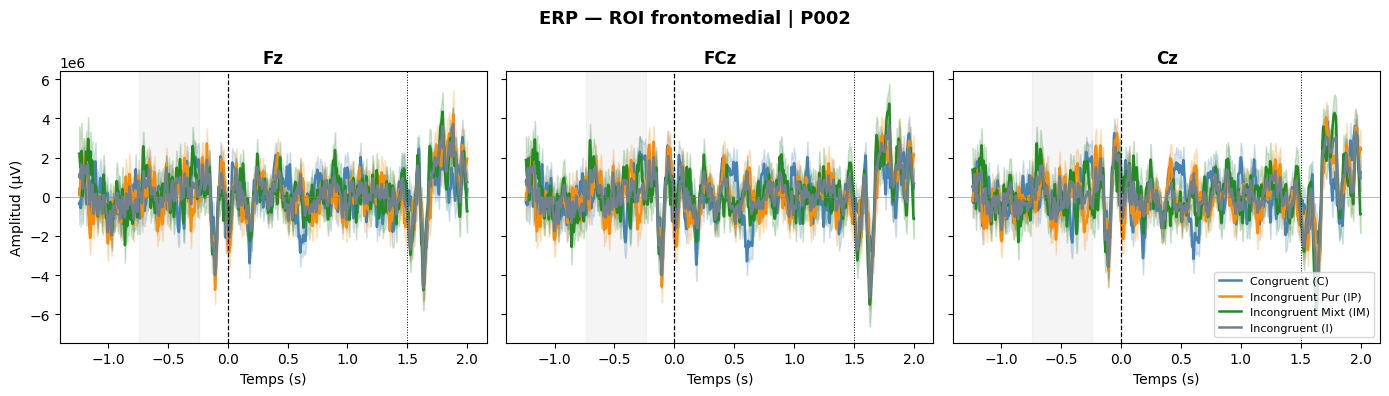

In [54]:
fig, axes = plt.subplots(1, len(ROI_FRONTAL), figsize=(14, 4), sharey=True)
times = epochs_all.times

for ax, ch in zip(axes, ROI_FRONTAL):
    for cond, ep in epochs_cond.items():
        data = ep.get_data(picks=[ch]).squeeze() * 1e6
        mean, sem = data.mean(axis=0), data.std(axis=0) / np.sqrt(len(ep))
        ax.plot(times, mean, label=LABELS[cond], color=COLORS[cond], linewidth=1.8)
        ax.fill_between(times, mean - sem, mean + sem, color=COLORS[cond], alpha=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08)
    ax.set_title(ch, fontsize=12, fontweight="bold")
    ax.set_xlabel("Temps (s)")

axes[0].set_ylabel("Amplitud (µV)")
axes[-1].legend(fontsize=8, loc="lower right")
fig.suptitle(f"ERP — ROI frontomedial | {SUBJ}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "erp_roi_frontomedial_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Theta power time-course (temps vs. potència, dB)
Potència theta (5–7 Hz) baseline-corregida, promig sobre Fz/FCz/Cz.
**Aquest és el plot central del TFG**: si el conflicte activa el sistema de monitoratge, IP ha de mostrar més potència theta que C durant la presentació de l'estímul.
Equivalent a la Figura 2B de l'article.

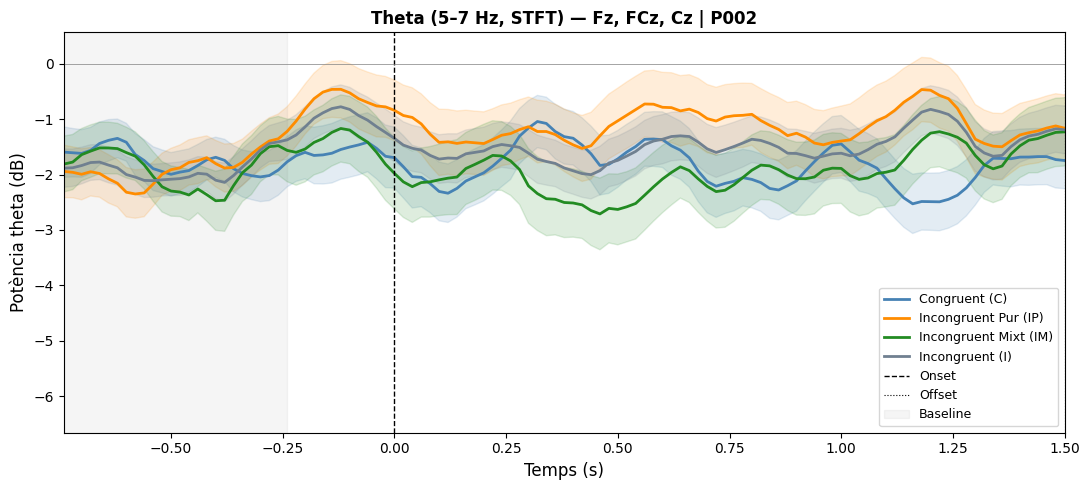

In [55]:
theta_tc = {}
for cond, ep in epochs_cond.items():
    t, mean_ts, sem_ts = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7), baseline=BASELINE)
    theta_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in theta_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència theta (dB)", fontsize=12)
ax.set_title(f"Theta (5–7 Hz, STFT) — Fz, FCz, Cz | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "theta_5_7hz_stft_roi_frontal_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### TFR map diferencial. Figura 3 (A i C)
Diferència de potència (IP−C i IP−IM) per tot l'espectre i tots els elèctrodes. 
Vermell = més potència en IP; blau = menys. Les bandes theta i alpha marcades.

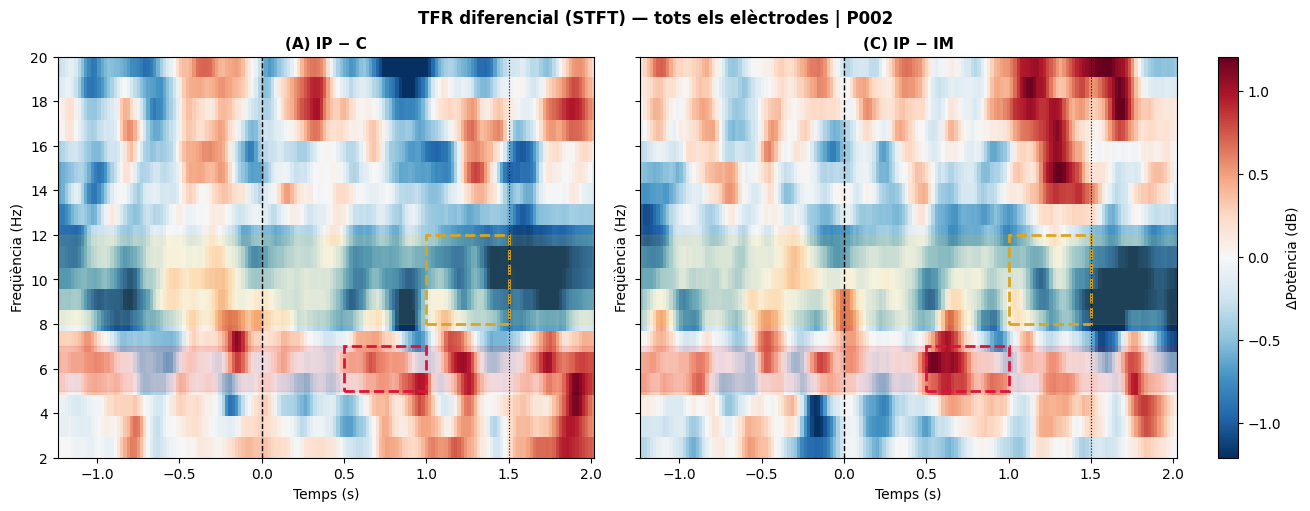

In [56]:
tfr_cond_mean = {}
for cond, ep in epochs_cond.items():
    f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)
    tfr_cond_mean[cond] = {"freqs": f, "times": t, "mean_db": mean_db}  # (n_freq, n_t)

contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
raw_diffs = [tfr_cond_mean[ca]["mean_db"] - tfr_cond_mean[cb]["mean_db"] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    t = tfr_cond_mean[ca]["times"]
    f = tfr_cond_mean[ca]["freqs"]
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[t[0], t[-1], f[0], f[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.12)
    ax.axhspan(8, 12, color="gold", alpha=0.10)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPotència (dB)")
fig.suptitle(f"TFR diferencial (STFT) — tots els elèctrodes | {SUBJ}", fontsize=12, fontweight="bold")
plt.savefig(FIGURES_DIR / "tfr_diferencial_stft_tots_electrodes_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Alpha suppression. Figura 4A
Potència alpha (8–12 Hz) sobre ROI parieto-occipital. Supressió alpha = major activació visual.
Hipòtesi: IP i IM haurien de mostrar més supressió (valors més baixos) que C.

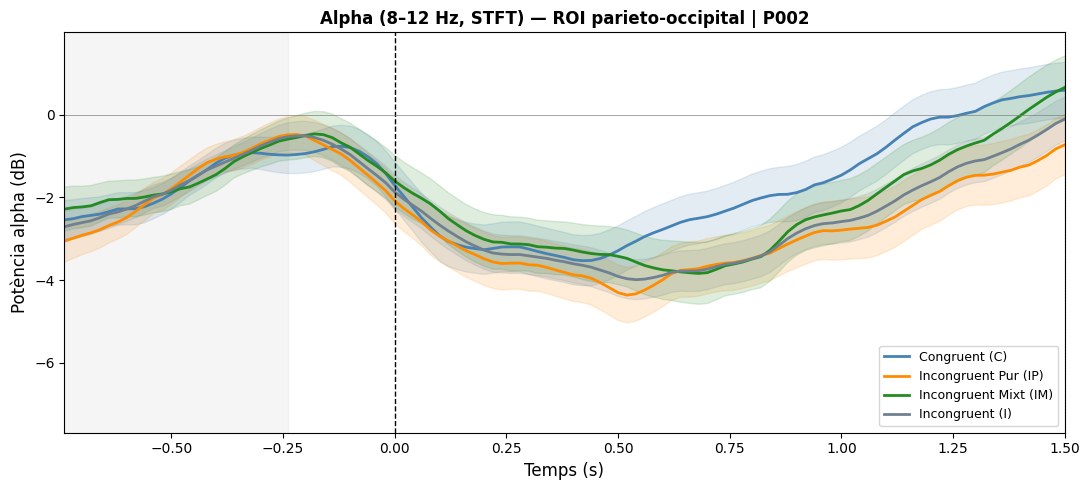

In [57]:
alpha_tc = {}
for cond, ep in epochs_cond.items():
    po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
    if not po_ok:
        continue
    t, mean_ts, sem_ts = stft_band_timecourse(ep, po_ok, band=(8, 12), baseline=BASELINE)
    alpha_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in alpha_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència alpha (dB)", fontsize=12)
ax.set_title(f"Alpha (8–12 Hz, STFT) — ROI parieto-occipital | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alpha_8_12hz_stft_roi_parieto_occipital_individual.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Part 3: Mitjana sobre tots els subjectes

El loop carrega cada subjecte, calcula els TFRs theta i alpha, i acumula els time-courses.
Al final es fa la mitjana entre subjectes i es reploten els mateixos gràfics amb SEM real entre subjectes.

In [58]:
# Acumuladors
all_theta = {cond: [] for cond in COND_EVENTS}
all_alpha = {cond: [] for cond in COND_EVENTS}
subjectes_inclosos = []
times_ga = None


def power_ts(ep, picks, band):
    times, mean_ts, _ = stft_band_timecourse(ep, picks, band=band, baseline=BASELINE)
    return times, mean_ts


for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    ep_all, ep_cond = load_subject(fif_path)

    for cond, ep in ep_cond.items():
        # Theta (ROI frontal)
        t, ts = power_ts(ep, ROI_FRONTAL, band=(5, 7))
        all_theta[cond].append(ts)
        if times_ga is None:
            print(f"Guardant times de la GA a partir de {subj_id}...")
            times_ga = t

        # Alpha (ROI parieto-occipital)
        po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
        if po_ok:
            _, ts = power_ts(ep, po_ok, band=(8, 12))
            all_alpha[cond].append(ts)

    subjectes_inclosos.append(subj_id)
    del ep_cond, ep_all
    gc.collect()

print(f"\nInclosos : {len(subjectes_inclosos)} — {subjectes_inclosos}")

Guardant times de la GA a partir de P002...


KeyboardInterrupt: 

### TFR map diferencial (grand average)
Mateix càlcul que al cas individual, però recorrent els subjectes un a un i acumulant només el mapa TFR mitjà per condició per reduir l'ús de memòria.

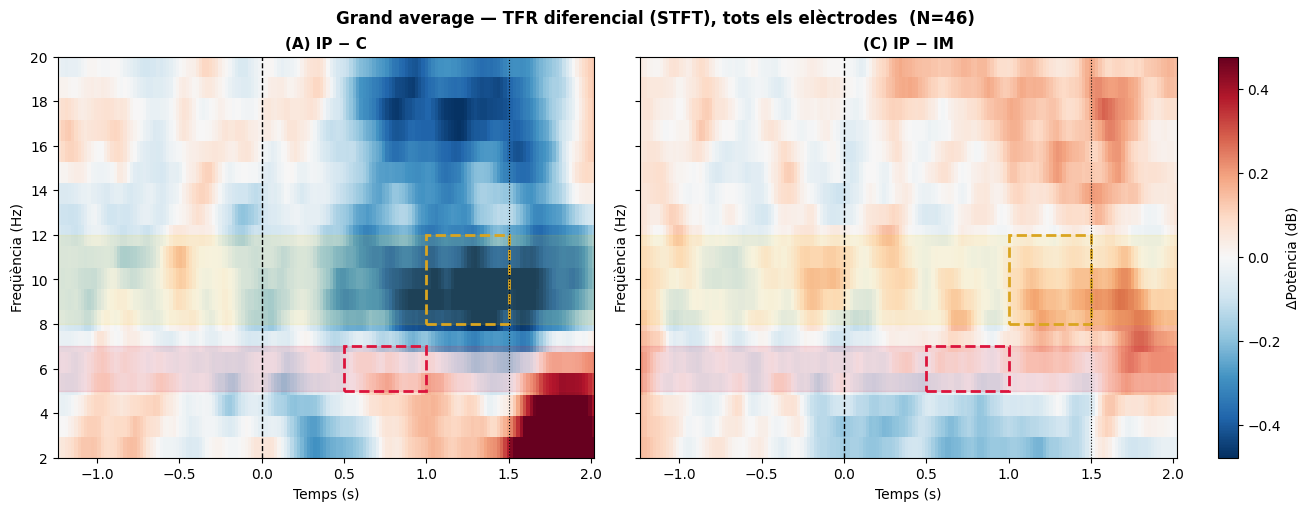

Subjectes contribuents per condició:
  Congruent (C)           : 47
  Incongruent Pur (IP)    : 47
  Incongruent Mixt (IM)   : 46
  Incongruent (I)         : 47
  Errors                  : 33


In [ ]:
ga_tfr_sum = {}
ga_tfr_n = {cond: 0 for cond in COND_EVENTS}
freqs_tfr_ga, times_tfr_ga = None, None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    try:
        for cond, ep in ep_cond.items():
            f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)

            if cond not in ga_tfr_sum:
                ga_tfr_sum[cond] = np.zeros_like(mean_db, dtype=np.float64)

            ga_tfr_sum[cond] += mean_db
            ga_tfr_n[cond] += 1

            if freqs_tfr_ga is None or times_tfr_ga is None:
                freqs_tfr_ga, times_tfr_ga = f, t
    finally:
        del ep_cond, ep_all
        gc.collect()

tfr_ga_mean = {}
for cond, sum_db in ga_tfr_sum.items():
    if ga_tfr_n[cond] > 0:
        tfr_ga_mean[cond] = sum_db / ga_tfr_n[cond]

if freqs_tfr_ga is None or times_tfr_ga is None:
    raise RuntimeError("No s'ha pogut calcular cap TFR per al grand average.")

contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
raw_diffs = [tfr_ga_mean[ca] - tfr_ga_mean[cb] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[times_tfr_ga[0], times_tfr_ga[-1], freqs_tfr_ga[0], freqs_tfr_ga[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.12)
    ax.axhspan(8, 12, color="gold", alpha=0.10)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPotència (dB)")

conds_used = sorted({ca for _, ca, _, _ in contrasts} | {cb for _, _, cb, _ in contrasts})
n_tfr = min(ga_tfr_n[c] for c in conds_used)
fig.suptitle(
    f"Grand average — TFR diferencial (STFT), tots els elèctrodes  (N={n_tfr})",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(FIGURES_DIR / "grand_average_tfr_diferencial_stft_tots_electrodes.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subjectes contribuents per condició:")
for cond in COND_EVENTS:
    print(f"  {LABELS[cond]:24s}: {ga_tfr_n[cond]:2d}")

### Theta power time-course
Cada línia és la mitjana entre subjectes. L'àrea ombrejada és el SEM entre subjectes (no entre trials ni entre canals com en els plots individuals).

In [ ]:
def plot_timecourse_ga(accumulator, times, ylabel, title, output_name):
    """Plot de grand average amb SEM entre subjectes."""
    fig, ax = plt.subplots(figsize=(11, 5))
    n_subj = len(next(iter(accumulator.values())))

    for cond, ts_list in accumulator.items():
        mat = np.array(ts_list)  # (n_subjectes, n_times)
        mean_ga = mat.mean(axis=0)
        sem_ga = mat.std(axis=0) / np.sqrt(len(ts_list))
        ax.plot(times, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
        ax.fill_between(times, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
    ax.set_xlabel("Temps (s)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"{title}  (N={n_subj})", fontsize=12, fontweight="bold")
    ax.set_xlim(FULL_TRIAL)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / output_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_timecourse_ga(
    all_theta,
    times_ga,
    ylabel="Potència theta (dB)",
    title="Grand average — Theta (5–7 Hz), Fz/FCz/Cz",
    output_name="grand_average_theta_5_7hz_roi_frontal.png",
)

### Alpha suppression

In [ ]:
plot_timecourse_ga(
    all_alpha,
    times_ga,
    ylabel="Potència alpha (dB)",
    title="Grand average — Alpha (8–12 Hz), ROI parieto-occipital",
    output_name="grand_average_alpha_8_12hz_roi_parieto_occipital.png",
)

### ERP (Event-Related Potential)
Mitjana del senyal en el domini temporal. Aquí cal recalcular perquè necessitem les dades en brut (µV), no els TFRs.

In [ ]:
all_erp = {cond: [] for cond in COND_EVENTS}  # (n_subjectes, n_times) per canal promig
times_erp = None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    if times_erp is None:
        times_erp = ep_all.times
    for cond, ep in ep_cond.items():
        # Promig sobre trials i sobre canals ROI → (n_times,)
        data = ep.get_data(picks=ROI_FRONTAL).mean(axis=0).mean(axis=0) * 1e6
        all_erp[cond].append(data)

    del ep_cond, ep_all
    gc.collect()

fig, ax = plt.subplots(figsize=(11, 5))
n_subj = len(subjectes_inclosos)
for cond, ts_list in all_erp.items():
    mat = np.array(ts_list)
    mean_ga = mat.mean(axis=0)
    sem_ga = mat.std(axis=0) / np.sqrt(n_subj)
    ax.plot(times_erp, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times_erp, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Amplitud (µV)", fontsize=12)
ax.set_title(f"Grand average — ERP, Fz/FCz/Cz  (N={n_subj})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "grand_average_erp_fz_fcz_cz.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 4: Cansament al llarg de la sessió

Pregunta de recerca: **Hi ha un cansament visible?**

Responem la pregunta en dues parts separades:
1. **Errors cap al final**: mirem si la taxa d'errors augmenta del primer terç a l'últim terç de trials.
2. **Disminució de l'amplitud ERP**: mirem si l'amplitud ERP disminueix del primer terç a l'últim terç.

Per cada part fem:
- **Anàlisi global** (agregat sobre subjectes)
- **Anàlisi per subjecte** (taula individual de tendències)

In [ ]:
# Càlcul únic de mètriques de cansament i sèries ERP per subjecte
df_fatigue, subject_amp_series = compute_fatigue_metrics(DATA_DIR)

if df_fatigue.empty:
    raise RuntimeError("No s'han pogut calcular mètriques de cansament.")

print(f"Subjectes analitzats per cansament: {len(df_fatigue)}")

Subjectes analitzats per cansament: 47


PART A — Errors cap al final
Global (macro-average per subjecte):
  Error T1 (inici) : 0.0062
  Error T2 (mig)   : 0.0107
  Error T3 (final) : 0.0107
  Delta T3-T1      : +0.004
  Subjectes amb augment d'errors (T3>T1): 19/47
  Test de signe (unilateral, augment): p=0.1405


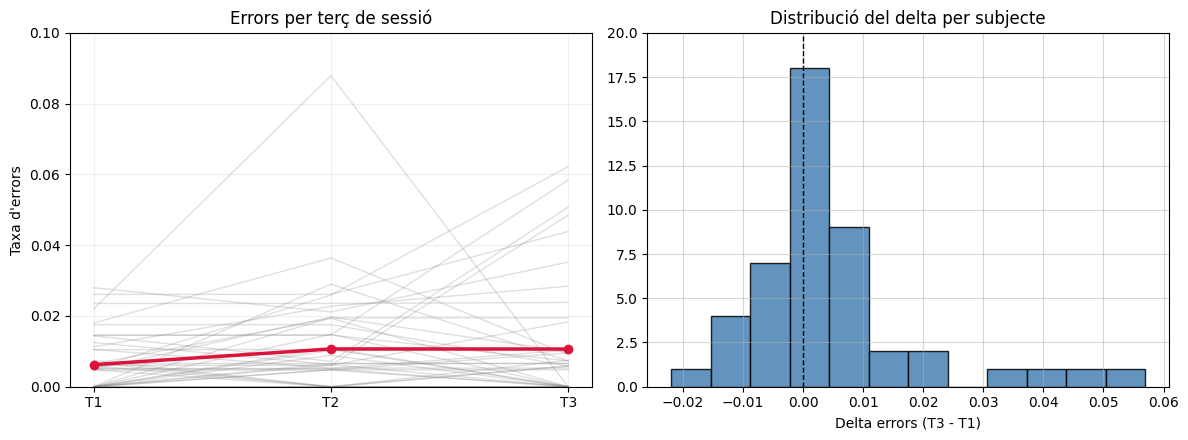

,subjecte,n_trials,error_t1,error_t2,error_t3,error_delta_t3_t1,error_slope,error_rho,error_p
0,P017,579,0.0052,0.0259,0.0622,0.0570,0.0749,0.1247,0.0026
1,P040,495,0.0000,0.0061,0.0485,0.0485,0.0719,0.1558,0.0005
2,P024,411,0.0146,0.0146,0.0584,0.0438,0.0381,0.0654,0.1857
3,P014,416,0.0144,0.0072,0.0507,0.0363,0.0588,0.1111,0.0235
4,P0005,462,0.0000,0.0195,0.0195,0.0195,0.0327,0.0836,0.0727
5,P020,344,0.0261,0.0261,0.0439,0.0178,0.0272,0.0448,0.4071
6,P051,529,0.0113,0.0227,0.0284,0.0171,0.0182,0.0369,0.3974
7,P035,494,0.0061,0.0061,0.0183,0.0122,0.0237,0.0686,0.1280
8,P0009,585,0.0000,0.0103,0.0103,0.0103,0.0142,0.0499,0.2284
9,P033,630,0.0000,0.0048,0.0095,0.0095,0.0156,0.0655,0.1006


In [ ]:
# PART A — Errors cap al final
alpha = 0.05

# Tendència global (macro, mateix pes per subjecte)
global_err_t1 = float(df_fatigue["error_t1"].mean())
global_err_t2 = float(df_fatigue["error_t2"].mean())
global_err_t3 = float(df_fatigue["error_t3"].mean())
global_err_delta = float(df_fatigue["error_delta_t3_t1"].mean())

n_pos = int((df_fatigue["error_delta_t3_t1"] > 0).sum())
n_neg = int((df_fatigue["error_delta_t3_t1"] < 0).sum())
n_nonzero = n_pos + n_neg
p_sign = binomtest(n_pos, n=n_nonzero, p=0.5, alternative="greater").pvalue if n_nonzero > 0 else np.nan

print("PART A — Errors cap al final")
print("Global (macro-average per subjecte):")
print(f"  Error T1 (inici) : {global_err_t1:.4f}")
print(f"  Error T2 (mig)   : {global_err_t2:.4f}")
print(f"  Error T3 (final) : {global_err_t3:.4f}")
print(f"  Delta T3-T1      : {global_err_delta:+.3f}")
print(f"  Subjectes amb augment d'errors (T3>T1): {n_pos}/{len(df_fatigue)}")
print(f"  Test de signe (unilateral, augment): p={p_sign:.4g}")

# Visualització global + trajectòries individuals
x = np.array([1, 2, 3])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for _, r in df_fatigue.iterrows():
    axes[0].plot(x, [r["error_t1"], r["error_t2"], r["error_t3"]], color="gray", alpha=0.25, linewidth=1)

axes[0].plot(x, [global_err_t1, global_err_t2, global_err_t3], color="crimson", marker="o", linewidth=2.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["T1", "T2", "T3"])
axes[0].set_ylabel("Taxa d'errors")
axes[0].set_title("Errors per terç de sessió")
axes[0].set_ylim(0, 0.1)
axes[0].grid(alpha=0.2)

axes[1].hist(df_fatigue["error_delta_t3_t1"], bins=12, color="steelblue", edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("Delta errors (T3 - T1)")
axes[1].set_title("Distribució del delta per subjecte")
axes[1].set_ylim(0, 20)
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "errors_cap_al_final_i_distribucio_delta.png", dpi=300, bbox_inches="tight")
plt.show()

# Resum per subjecte
cols_error = [
    "subjecte",
    "n_trials",
    "error_t1",
    "error_t2",
    "error_t3",
    "error_delta_t3_t1",
    "error_slope",
    "error_rho",
    "error_p",
]
df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4).to_csv(
    TABLES_DIR / "fatiga_errors_subjectes.csv", index=False
)
print(f"Desat taula: {TABLES_DIR / 'fatiga_errors_subjectes.csv'}")
display(df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4))

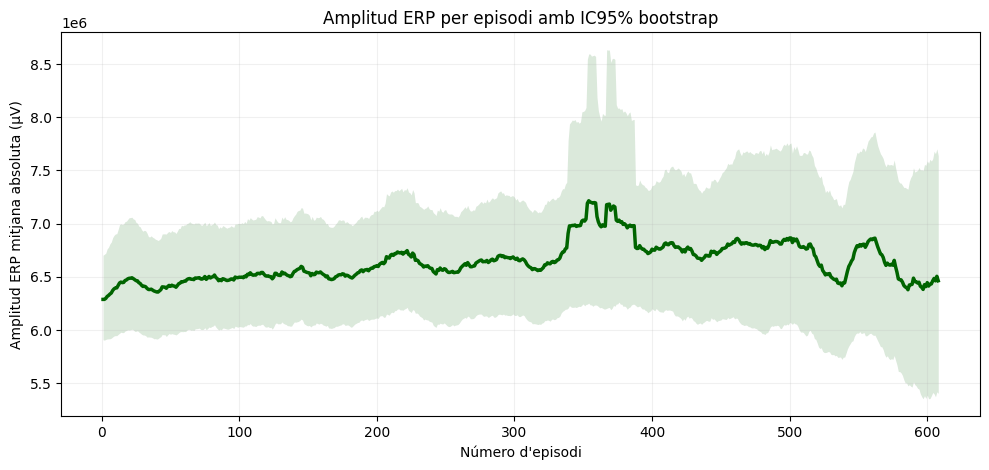

Subjectes inclosos: 47
Episodis màxims: 651


In [ ]:
# PART B — Amplitud ERP per episodi amb IC95% bootstrap (tots els subjectes)
subject_labels = sorted(subject_amp_series.keys())
subject_series = [subject_amp_series[s] for s in subject_labels]

curve = build_bootstrap_curve(
    subject_series=subject_series,
    n_boot=BOOT_N,
    smooth_win=SMOOTH_WIN,
    min_subjects=5,
    seed=42,
)

if curve is None:
    print("No hi ha dades ERP per construir la corba.")
else:
    x = curve["x"]
    valid = curve["valid"]
    mean_s = curve["mean"]
    low_s = curve["low"]
    high_s = curve["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5)

    ax.set_xlabel("Número d'episodi")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("Amplitud ERP per episodi amb IC95% bootstrap")
    ax.grid(alpha=0.18)

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_ic95_bootstrap_tots_subjectes.png", dpi=300, bbox_inches="tight"
    )
    plt.show()

    print(f"Subjectes inclosos: {curve['n_subjects']}")
    print(f"Episodis màxims: {curve['max_n']}")

In [ ]:
# Mateix plot de la cel·la anterior, però només per subjectes amb augment d'errors
# significatiu a T3 vs T1 (test binomial unilateral aproximat amb taxes per terç)
alpha = ALPHA
selected_subjects = []

for _, r in df_fatigue.iterrows():
    n_trials = int(r["n_trials"])
    bins = np.array_split(np.arange(n_trials), N_BINS)
    n1 = len(bins[0])
    n3 = len(bins[-1])

    e1 = int(round(float(r["error_t1"]) * n1))
    e3 = int(round(float(r["error_t3"]) * n3))

    if (e1 + e3) > 0 and e3 / max(n3, 1) > e1 / max(n1, 1):
        p_inc = binomtest(e3, n=e1 + e3, p=n3 / (n1 + n3), alternative="greater").pvalue
        if p_inc < alpha:
            selected_subjects.append(r["subjecte"])

print(f"Subjectes seleccionats (augment significatiu T3>T1): {len(selected_subjects)}")
print(selected_subjects)

subject_series_sig = [subject_amp_series[s] for s in selected_subjects if s in subject_amp_series]

curve_sig = build_bootstrap_curve(
    subject_series=subject_series_sig,
    n_boot=BOOT_N,
    smooth_win=SMOOTH_WIN,
    min_subjects=3,
    seed=42,
)

if curve_sig is None:
    print("No hi ha subjectes que compleixin el criteri.")
else:
    x = curve_sig["x"]
    valid = curve_sig["valid"]
    mean_s = curve_sig["mean"]
    low_s = curve_sig["low"]
    high_s = curve_sig["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5)

    ax.set_xlabel("Número d'episodi")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("Amplitud ERP per episodi (subjectes amb augment d'errors significatiu T3>T1)")
    ax.grid(alpha=0.18)

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_subjectes_amb_augment_errors_significatiu.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

NameError: name 'df_fatigue' is not defined

Podem confirmar que hi ha un petit augment d'errors a partir de la meitat de la sessió, però no és un augment dramàtic, i es manté bastant estable fins al final del test. Pel que fa a l'amplitud ERP, definitivament no hi ha una disminució clara com esperava, sinó que de fet augmenta al llarg del temps. Això no confirma que no hi hagi cansament, però podria ser que més activitat cerebral de fet fos un senyal que els subjectes pensaven en altres coses per distreure's o per no avorrir-se. En qualsevol cas, no hi ha evidència clara de cansament en aquestes dades, però tampoc es pot descartar completament. Caldria fer més anàlisis de canals específics o fins i tot experiments nous per explorar aquesta qüestió més a fons. En els dos subjectes amb significativament més errors al final, també es veu un augment d'amplitud ERP, el que reforça la idea que aquest augment no és un senyal de major atenció sinó possiblement de distracció o avorriment.